# PHYB57 · Chapter 12「科学绘图与动画」逐行人话版

> 2D 绘图 → 标题 / 标签 / 图例 / 样式 → 3D（线、面、散点）→ 地图（Cartopy）→ 动画 → 存成 mp4
> 对应课件：`PHYB57_C12.pdf`（9 页 Keynote 幻灯片）

这一章和前几章都不一样：**课件里全是代码**，而且每一段都能当场跑出图来。

所以这份 notebook 干三件事：

1. **把课件里每一段代码原样跑一遍** —— 代码在前、图在后，对不对自己看；
2. **逐行讲解每一段代码** —— 每个代码格后面都跟一张「📖 这一格在做什么」的表；
3. **把「照抄会出错」的地方挑出来** —— 本章一共 **8 处 📌 勘误**，都在下面标出来了。

## 怎么读

- 「**课件原文**」是幻灯片上的英文，**一字未改**（包括它自己的笔误）
- 「**人话版**」是把那几段英文翻译成人话
- 「**📖 这一格在做什么**」是逐行翻译，左边标行号，右边说人话
- ⚠️ = **容易踩的坑**
- 💡 = **顺带一提 / 小技巧**
- 🧪 = **补充实验** —— 课件里没有，但能帮你把上面的东西真正搞懂
- 📌 = **勘误** —— 课件说法不严谨、或照抄会出错的地方

## 目录

| 页码 | 小节 | 主题 | 你会得到什么 |
|---|---|---|---|
| P1 | §1 | 2D 绘图入门：`plot(x, y)`、线型、交互后端 | 两条曲线 + 一张线型/标记速查表 |
| P2 | §2 | 标题 / 标签 / 图尺寸 / 图例 / 全局样式 | 带图例的双曲线图 + 样式名实测 |
| P3 | §3 | 3D 线图：`mplot3d`、参数方程 | 一条 3D 螺旋线 + 视角实验 |
| P4 | §4 | 3D 曲面与散点：`meshgrid` | 一张 sin·cos 曲面 + 一张 3D 散点 |
| P5 | §5 | 地图基础：经纬度、投影 | 不装任何库就能画出来的「地图」 |
| P6 | §6 | Cartopy 画世界地图 | PlateCarree 世界地图 |
| P7 | §7 | 进阶地图：缩放 + 陆地/海洋/边界 | 旧金山湾 110m vs 10m 对比 |
| P8 | §8 | 动画：`FuncAnimation` | 会动的正弦波（notebook 里真能看） |
| P9 | §9 | 把动画存成 mp4 | 一个 GIF +（有 ffmpeg 时的）mp4 |
| — | §10 | 收尾 | 8 处勘误汇总表 + 检查清单 |

## 开跑之前先记住这一句

> **matplotlib 的每一张图，都是「一层一层叠上去」的：先有 Figure（画布），再有 Axes（坐标区），最后才有 Line / Marker（具体的东西）。**

课件里的代码经常把这几层混着写（`plt.plot` 光杆画一条线、`plt.axes` 直接建坐标区、`fig, ax = plt.subplots()` 一次建两层）。搞不清谁是谁，图一出问题就无从下手。

这一章每段代码我都会指明：**它动的是哪一层**。

## §0 · 开跑之前

本章需要的「依赖」分三档：

| 档次 | 依赖 | 用在哪 | 没装会怎样 |
|---|---|---|---|
| **必需** | `numpy`、`matplotlib` | 全章 | 跑不动 |
| **可选** | `cartopy` | §6、§7（地图） | 那两节自动跳过，打印安装提示 |
| **可选** | `ffmpeg`（注意：**不是 Python 库**，是外部程序） | §9（存 mp4） | §9 改存 GIF，其余照跑 |

```bash
# 必需
pip install numpy matplotlib

# 地图（会顺带装上 pyproj / shapely / pyshp）
pip install cartopy

# 存 mp4 需要外部程序 ffmpeg（macOS）
brew install ffmpeg
```

先跑下面这一格：它会把环境**体检一遍**，谁在、谁不在，一目了然。

In [8]:
%matplotlib inline
import sys, importlib

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d       # 3D 工具箱：不导入它，projection='3d' 会找不到

print('Python      ', sys.version.split()[0])
print('numpy       ', np.__version__)
print('matplotlib  ', matplotlib.__version__)
print('后端 backend ', matplotlib.get_backend())
print()
print('--- 可选依赖体检 ---')
for name in ['cartopy', 'folium', 'PIL', 'seaborn', 'imageio']:
    try:
        mod = importlib.import_module(name)
        print('  [有] %-10s %s' % (name, getattr(mod, '__version__', '')))
    except ImportError:
        print('  [无] %-10s' % name)

# --- 让图里的中文正常显示：不设这一段，图里的中文会变成一个个方框 □□□ ---
from matplotlib import font_manager

CJK_CANDIDATES = [
    'PingFang SC', 'Hiragino Sans GB',                                 # macOS
    'Heiti TC', 'STHeiti', 'Songti SC', 'Arial Unicode MS',            # macOS 备选
    'Microsoft YaHei', 'SimHei',                                       # Windows
    'Noto Sans CJK SC', 'WenQuanYi Micro Hei',                         # Linux
]
installed = {f.name for f in font_manager.fontManager.ttflist}
found = [name for name in CJK_CANDIDATES if name in installed]


def use_cjk_font():
    """把中文字体装回 matplotlib 的全局配置。

    ⚠️ plt.style.use(...) 会把 rcParams 整个重置，中文设置会跟着丢。
       所以每次换完样式，都要再调用一次这个函数（§2.4 会踩到这个坑）。
    """
    if found:
        matplotlib.rcParams['font.sans-serif'] = found + ['DejaVu Sans']
        matplotlib.rcParams['axes.unicode_minus'] = False   # 负号改用 ASCII 减号


use_cjk_font()
print('中文字体已启用：', found[0] if found else '（没找到，图里的中文会变方框）')

Python       3.13.9
numpy        2.3.5
matplotlib   3.10.6
后端 backend  inline

--- 可选依赖体检 ---
  [无] cartopy   
  [无] folium    
  [有] PIL        12.0.0
  [有] seaborn    0.13.2
  [有] imageio    2.37.2
中文字体已启用： Hiragino Sans GB


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1 | `%matplotlib inline` | **魔法命令**（不是 Python 语句）。意思是「把图直接渲染成 PNG 贴在这一格下面」。Jupyter 默认就是它，但写出来更清楚 —— §1.4 会讲不写它的后果 |
| 2 | `import sys, importlib` | `sys` 用来查 Python 版本；`importlib` 用来**在运行时按名字找库**（体检表那几行靠它） |
| 5 | `import numpy as np` | 数值计算。本章主要用它造数据：`linspace`、`arange`、`meshgrid`、`sin` |
| 6 | `import matplotlib` | 库本体。这里只为了拿版本号 —— 画图不用它，用下一行的 `pyplot` |
| 7 | `import matplotlib.pyplot as plt` | **本章的主角**。`pyplot` 是一套「状态机」式接口：`plt.plot(...)` 会自己找当前画布、当前坐标区 |
| 8 | `from mpl_toolkits import mplot3d` | 3D 工具箱。⚠️ 它**不提供函数给你调用**，作用是「注册」`projection='3d'` 这个能力。少这一行，§3 的 `plt.axes(projection='3d')` 会报错 |
| 15-20 | `for name in [...]:` | 挨个试着导入。用 `try/except ImportError` 而不是直接 `import`，是为了**缺库也不崩** —— 后面的地图/动图小节会用到这几个探测结果 |
| 22 | `# 让图里的中文正常显示...` | 注释。**这一段是中文用户最需要的东西**，原因见下面 ⚠️ |
| 23 | `from matplotlib import font_manager` | matplotlib 的字体管理器，能列出系统里**所有**已安装字体 |
| 25-30 | `CJK_CANDIDATES = [...]` | **按优先级**列出各系统常见的中文字体名：macOS 两组、Windows 一组、Linux 一组 |
| 31 | `installed = {f.name for f in ...}` | 集合推导式：把「系统里真正装了的字体名」收成一个**集合**（查找是 O(1)，比列表快） |
| 32 | `found = [name for name in CJK_CANDIDATES if name in installed]` | 按优先级顺序过滤，只留下真实存在的。**列表的顺序 = 优先级顺序** |
| 35-43 | `def use_cjk_font(): ...` | **把它包成一个函数**，而不是直接写两行 `rcParams`。原因见下面第二个 ⚠️ |
| 41-43 | `rcParams['font.sans-serif'] = ...` | 把找到的中文字体**插到最前面**，末尾接 `DejaVu Sans` 兜底（画英文和数学符号用）。`axes.unicode_minus = False` 让负号用 ASCII 减号 |
| 46 | `use_cjk_font()` | 立刻调用一次，让本章开头就生效 |
| 47 | `print('中文字体已启用：', ...)` | 打印用的是哪个字体。**没找到也只警告、不报错**，后面的图照画，只是中文显示为方框 |

> ⚠️ **为什么必须做这件事？** matplotlib 的默认字体是 `DejaVu Sans`，它**一个汉字都没有**。所以 `plt.title('中文标题')` 不会报错，但会画出一排**方框**（□□□□）。这是中文用户问得最多的问题，没有之一。
>
> ⚠️ **为什么要包成 `use_cjk_font()` 这个函数？** 因为 **`plt.style.use(...)` 会把 `rcParams` 整个重置**（§2.4 讲过），中文设置会一起丢掉 —— 于是前面画得好好的中文，从某一格开始突然全变方框。有了这个函数，只要在「换完样式」之后补一句 `use_cjk_font()` 就行。
>
> ⚠️ **`axes.unicode_minus = False` 这行也容易漏**：很多中文字体里的「减号」和 ASCII 减号**不是同一个字符**。一旦启用了中文字体，坐标轴上的 `-5` 会莫名其妙变成 `□5`。设成 `False` 之后，matplotlib 改用 ASCII 减号，负号立刻正常。
>
> 💡 **换一台机器跑，字体名要跟着变**。查你机器上有什么中文字体的办法：
> ```python
> import matplotlib
> print(sorted({f.name for f in matplotlib.font_manager.fontManager.ttflist}))
> ```
> ⚠️ 顺带一个实测细节：很多 macOS 上**查不到 `'PingFang SC'`**（系统只注册了 `'PingFang HK'`）。所以上面那张候选表里，我把 `'PingFang SC'` 排在第一位但**并不依赖它** —— `found` 会自动跳过不存在的名字往下找。这种「给一串候选、挑第一个能用的」写法，比硬编码某个字体名健壮得多。

> 💡 **一个值得养成的习惯**：新开一个 notebook，第一格就打印版本号。这一章里就有好几个「以前能跑、现在报错」的例子（§2.4 的 `seaborn-poster`、§9 的 ffmpeg），全都和版本有关。
>
> ⚠️ `get_backend()` 打印出来会是一长串 `module://matplotlib_inline.backend_inline`，别被它吓到 —— 这就是 inline 后端的全名。

---
# §1 · 2D 绘图入门（2D Plotting in Python）

## 课件原文（P1）

**Overview**

- Python's matplotlib package is essential for creating visual plots. It's commonly used in scientific and engineering contexts for data visualization.

**Basic Plotting Function**

- The function `plot(x, y)` creates a 2D plot from two lists or arrays, `x` and `y`, representing the coordinates.
- Example:

```python
x = [0, 1, 2, 3]
y = [0, 1, 4, 9]
plt.plot(x, y)
plt.show()
```

**Interactive Features**

- In Jupyter Notebooks, `%matplotlib notebook` allows interactive features like panning and zooming.
- `%matplotlib inline` disables these features for static images.

**Customization**

- Line and marker styles can be customized, e.g., `'ro'` plots red circles, while `'g--'` creates a dashed green line.

```python
x = np.linspace(-5,5,100)
plt.plot(x, x**2, 'g--')
plt.show()
```

## 人话版

- **matplotlib 是什么**：Python 里画图的事实标准，科研和工程里默认就用它
- **`plot(x, y)` 是什么**：给两组数（横坐标、纵坐标），把对应的点连成一条线。`x` 和 `y` 长度必须一样，第 i 个点就是 `(x[i], y[i])`
- **两种后端**：
  - `%matplotlib notebook` → 图是**活的**，能拖动、能缩放
  - `%matplotlib inline` → 图是**死的一张 PNG**，拖不动
- **风格字符串**：像 `'ro'`、`'g--'` 这种两三个字符的缩写，意思拆开看是 **「颜色 + 标记 + 线型」**，顺序随便：
  - `'ro'` = **r**ed + **o**（圆圈标记），没写线型 → 只有点、没有线
  - `'g--'` = **g**reen + **--**（虚线），没写标记 → 只有线、没有点

## §1.1 课件的第一个例子：`plot(x, y)`

课件给的是**片段** —— 它默认你已经 `import matplotlib.pyplot as plt` 过了。真正要跑，得把那一行补上。

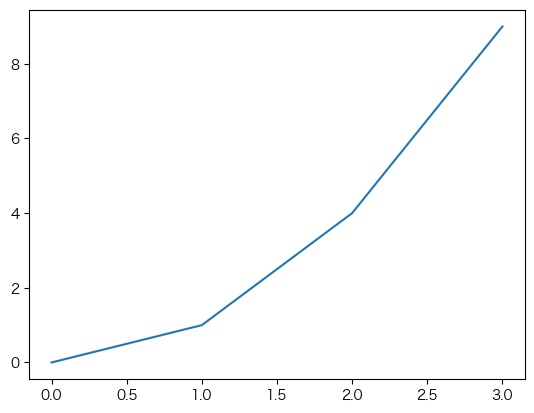

In [9]:
# 课件 P1 第一段：最朴素的 plot(x, y)
import matplotlib.pyplot as plt        # ⚠️ 幻灯片里省略了这一行，实际跑必须写

x = [0, 1, 2, 3]                       # 四个点的横坐标
y = [0, 1, 4, 9]                       # 对应的纵坐标 —— 注意正好是 x 的平方

plt.plot(x, y)                         # 把这四个点连成一条线
plt.show()                             # 把图画出来（Jupyter 里不写也会显示，写上更保险）

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `import matplotlib.pyplot as plt` | 课件片段里没有这行。**凡是要跑课件代码，先检查 import 齐了没** —— 这是新手最常见的报错来源（`NameError: name 'plt' is not defined`） |
| 4 | `x = [0, 1, 2, 3]` | 普通的 Python 列表就行，不一定要 numpy 数组 |
| 5 | `y = [0, 1, 4, 9]` | 必须和 `x` **等长**，否则报 `ValueError: x and y must have same first dimension` |
| 7 | `plt.plot(x, y)` | 画线。注意它**不返回图**，只是往「当前坐标区」里塞了一条线 |
| 8 | `plt.show()` | 把画布渲染出来 |

**看图说话**：输出的图里四个点是 `(0,0) (1,1) (2,4) (3,9)`，被一条蓝线连起来 —— 这就是 `y = x²` 在整数点上的采样。课件截图里那条上升的蓝线，就是它。

> 💡 **为什么叫「画线」而不是「画点」？** `plt.plot` 的默认行为是：**把数据点按顺序连起来，同时不画标记**。所以只给 4 个点，你就得到 3 段直线 —— 看起来「弯」是错觉，其实是折线。想只看点，要写 `plt.plot(x, y, 'o')`。

## §1.2 课件的第二个例子：`np.linspace` + 虚线

课件第二段换了个玩法：横坐标不再是手写的 4 个数，而是用 `np.linspace` 生成 100 个点。

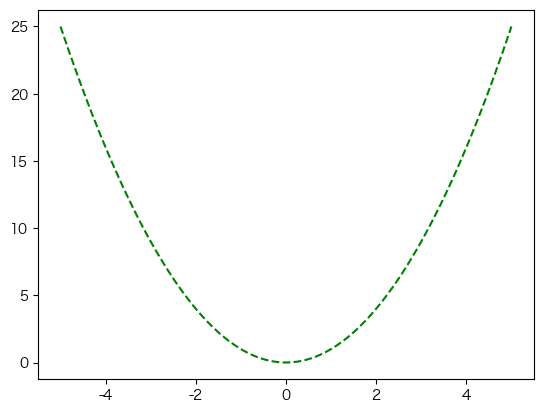

x 的个数： 100
前 3 个 x： [-5.        -4.8989899 -4.7979798]
后 3 个 x： [4.7979798 4.8989899 5.       ]
相邻两点间距： 0.10101010101010122


In [10]:
# 课件 P1 第二段：平滑曲线 + 虚线
x = np.linspace(-5, 5, 100)            # 从 -5 到 5，均匀取 100 个点
plt.plot(x, x**2, 'g--')               # 'g--' = 绿色 + 虚线
plt.show()

print('x 的个数：', x.size)
print('前 3 个 x：', x[:3])
print('后 3 个 x：', x[-3:])
print('相邻两点间距：', x[1] - x[0])

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `np.linspace(-5, 5, 100)` | **lin**early **space**：在 -5 和 5 之间**均匀**放 100 个点，**两端都包含**。所以第一个是 -5.0，最后一个是 5.0 |
| 3 | `plt.plot(x, x**2, 'g--')` | 第三个参数是**风格字符串**：`'g--'` = 绿色虚线。`x**2` 是逐元素平方，`x` 有 100 个数，`x**2` 也有 100 个数 |
| 4 | `plt.show()` | 渲染 |

**为什么看起来是光滑曲线？** 因为 100 个点足够密，折线肉眼分辨不出来。这就是「用直线段逼近曲线」—— 和 §3、§4 里 3D 曲面的做法是同一个思路。

> ⚠️ **`linspace` vs `arange`，别搞混**（§3、§4 马上就会遇到 `arange`）：

| | `np.linspace(start, stop, num)` | `np.arange(start, stop, step)` |
|---|---|---|
| 第三个参数是 | **点的个数** | **步长** |
| 末位 `stop` | **包含** | **不包含** |
| 例 | `linspace(-5, 5, 100)` → 100 个点，含 5.0 | `arange(-5, 5.1, 0.2)` → 步长 0.2，不含 5.1（所以课件故意写成 5.1） |

> 💡 课件在 P4 写 `np.arange(-5, 5.1, 0.2)`，那个 `5.1` 不是笔误，是**故意的** —— 因为 `arange` 不含终点，写成 5.0 就取不到 5.0 这个点。

## §1.3 🧪 风格字符串速查表

课件只举了 `'ro'` 和 `'g--'` 两个例子。但这两个字符位能填的东西远不止这些 —— 与其背，不如直接画出来。

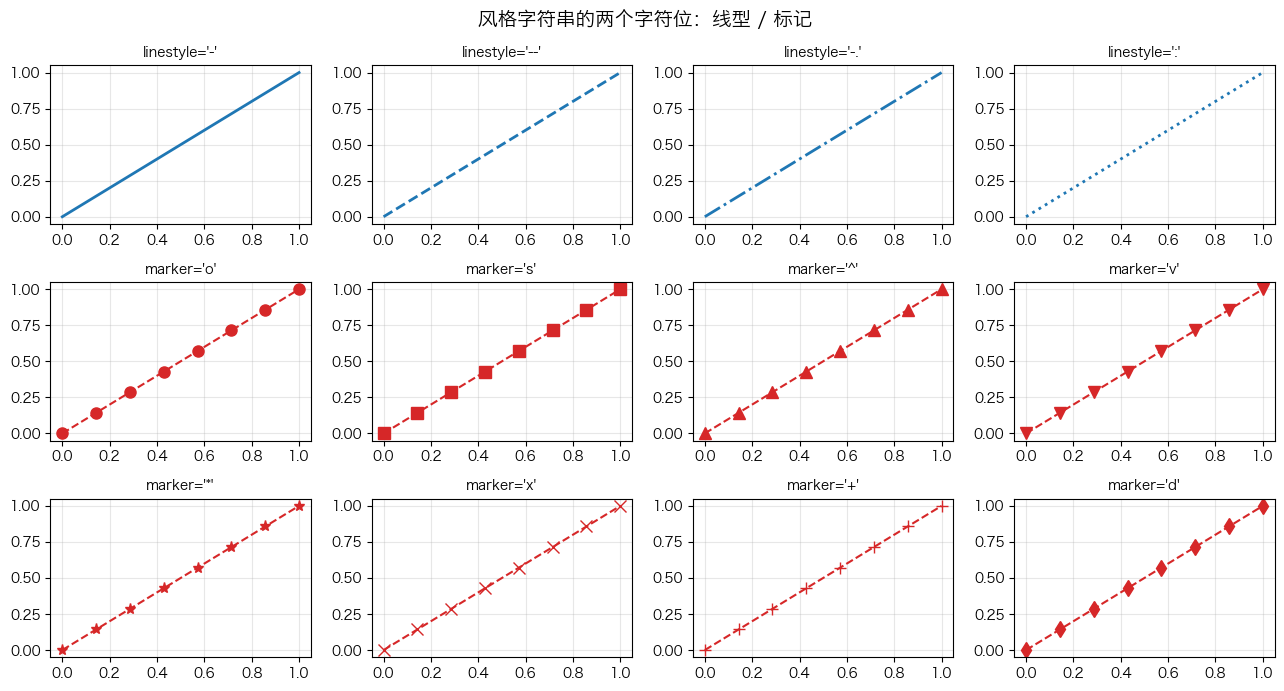

In [11]:
# 🧪 常用线型 + 标记一览
xs = np.linspace(0, 1, 8)

fig, axes = plt.subplots(3, 4, figsize=(13, 7))     # 3 行 4 列，共 12 个小坐标区

# 第一行：4 种线型
for ax, ls in zip(axes[0], ['-', '--', '-.', ':']):
    ax.plot(xs, xs, linestyle=ls, color='tab:blue', linewidth=2)
    ax.set_title('linestyle=%r' % ls, fontsize=10)

# 第二、三行：8 种标记（同时画出虚线，看清「点在线上」）
for ax, mk in zip(list(axes[1]) + list(axes[2]),
                  ['o', 's', '^', 'v', '*', 'x', '+', 'd']):
    ax.plot(xs, xs, linestyle='--', marker=mk, color='tab:red', markersize=8)
    ax.set_title('marker=%r' % mk, fontsize=10)

for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.suptitle('风格字符串的两个字符位：线型 / 标记', fontsize=14)
plt.tight_layout()
plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `xs = np.linspace(0, 1, 8)` | 只取 8 个点。点数正好够看清每个 marker 的形状 |
| 4 | `fig, axes = plt.subplots(3, 4, ...)` | **一次建两层**：`fig` 是画布，`axes` 是 3×4 的坐标区数组。这是比 `plt.plot` 更可控的写法，§2 开始一直用它 |
| 7 | `for ax, ls in zip(axes[0], [...])` | `axes[0]` 是第一行（4 个坐标区）。`zip` 把它们和 4 种线型一一配对 |
| 8 | `ax.plot(xs, xs, linestyle=ls, ...)` | ⚠️ 这里用的是**关键字参数** `linestyle=` 而不是位置参数 —— 效果和 `'--'` 一样，但可读性好得多 |
| 12 | `for ax, mk in zip(list(axes[1]) + list(axes[2]), [...])` | `axes[1]` 和 `axes[2]` 是**二维数组的两行**，`list(...)` 把它摊平成一个列表，再和 8 个 marker 配对 |
| 13 | `marker=mk` | 只给标记、不给线型：线型用我显式写的 `'--'` |
| 16-17 | `ax.grid(alpha=0.3)` | 给每个小图加淡网格；`alpha` 是透明度（0=全透明，1=不透明） |
| 19 | `plt.tight_layout()` | 自动调整子图间距，**防止标题和别的图重叠**。⚠️ 必须在 `show()` **之前**调用 |

> ⚠️ **`plt.subplots()` 的两个返回值别弄反**：是 `fig, ax`（**画布在前，坐标区在后**）。写反了不会立刻报错，但会在几行之后以 `AttributeError` 的形式炸出来，很难查。
>
> 💡 只有一个子图时习惯写成 `fig, ax = plt.subplots()`（`ax` 单数）；多个子图时是 `fig, axes = plt.subplots(2, 3)`，`axes` 是个二维数组，要用 `axes[行, 列]` 取。

## §1.4 📌 交互后端：课件那句 `%matplotlib notebook` 要小心

课件说：

> In Jupyter Notebooks, `%matplotlib notebook` allows interactive features like panning and zooming.

这句话**本身没错**，但它有个课件没说的后果：**`notebook` 后端画出来的图，不会被保存进 `.ipynb` 文件里**。

我们用当前 notebook 实测 `inline` 这边的行为，再把 `notebook` 那边的实测结果贴出来对比。

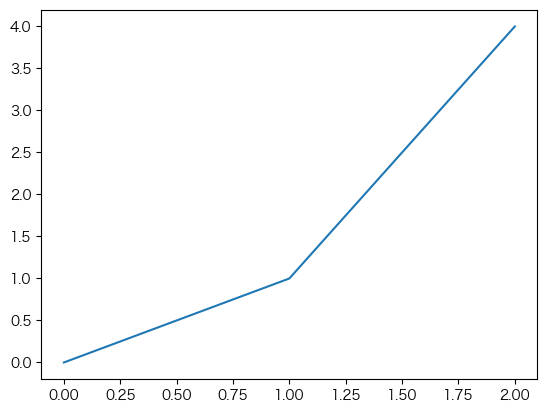

inline 后端：show() 之后，还挂在 pyplot 上的图 = 0 个
           -> 图已经被渲染成 PNG 交出去了，内存里不留东西


In [12]:
# 实验 A：inline 后端画完一张图，内核里还剩什么？
%matplotlib inline
plt.figure()
plt.plot([0, 1, 2], [0, 1, 4])
plt.show()

print('inline 后端：show() 之后，还挂在 pyplot 上的图 =', len(plt.get_fignums()), '个')
print('           -> 图已经被渲染成 PNG 交出去了，内存里不留东西')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `%matplotlib inline` | 确保后面用的是 inline 后端。**魔法命令要单独占一行**，不能和别的语句挤在一起 |
| 3 | `plt.figure()` | 空手开一块画布。返回的是 Figure 对象，这里我们不要它 |
| 4 | `plt.plot(...)` | 往「当前坐标区」塞一条线。`plt.figure()` 之后自动建了一个坐标区，所以这行能工作 |
| 5 | `plt.show()` | inline 后端会在这一步把图**渲染成 PNG** 塞进 notebook 的输出里，然后**把图关掉** |
| 7 | `len(plt.get_fignums())` | `get_fignums()` 返回「当前还开着的图」的编号列表。结果是 `0` —— 图**已经交出去、不再占内存** |

### 那 `notebook` 后端呢？下面是在同一台机器上实测的结果

```python
# 实验 B：把后端换成 notebook，重做上面的事
%matplotlib notebook
import matplotlib, matplotlib.pyplot as plt
print('backend after:', matplotlib.get_backend())    # -> notebook

plt.figure(); plt.plot([0, 1, 2], [0, 1, 4]); plt.show()
print('fig count:', len(plt.get_fignums()))          # -> 1   （图还活着！）
```

两处关键差异：

| | `inline` | `notebook` |
|---|---|---|
| `get_backend()` | `module://matplotlib_inline.backend_inline` | `notebook` |
| `show()` 之后 `get_fignums()` | `0`（图交出去了） | `1`（图变成活组件，还挂着） |
| 存进 `.ipynb` 的输出类型 | `image/png` ✅ **能导出** | `application/javascript` ❌ **没有图片** |

用 `jupyter nbconvert --execute` 跑一个含 `%matplotlib notebook` 的 notebook 时，终端还会打印：

```
[NbConvertApp] WARNING | No handler found for comm target 'matplotlib'
```

—— 意思是「这是个需要活 kernel 的交互组件，静态导出里没人接得住它」。

> 📌 **勘误 1（P1）**：课件推荐 `%matplotlib notebook`，但**它和你「导成 PDF / HTML 交作业」的需求是冲突的** —— 那样导出来的文件里，图是**空的**。
>
> 三种正确做法，按推荐顺序：
> 1. **要导出就老老实实用 `%matplotlib inline`**（本 notebook 的选择）；
> 2. 想要交互、又留在 notebook 里看：用 `%matplotlib widget`（**需要 `pip install ipympl`**）—— 这是 `notebook` 后端的现代替代品，在 JupyterLab 里也能用；
> 3. 已经写了 `notebook` 又要导出：把那一行改成 `inline`，然后**重新执行一遍**（只改代码不重跑，图还是不会出现）。

> 💡 顺便记住这个区别：`inline` 的图是「**快照**」，`widget` 的图是「**遥控器**」。交作业要的是快照。

---
# §2 · 给 2D 图加上标题、标签、图例和样式（P2）

## 课件原文（P2）

**Enhancing 2D Plots with Titles, Labels, and Legends**

**Adding Titles and Labels**

- Titles and axis labels provide context to the plot and can be customized for clarity.
- Example:

```python
plt.title('Quadratic Function')
plt.xlabel('X axis')
plt.ylabel('Y axis')
```

**Figure Size**

- Customizing the plot size can improve readability.

```python
plt.figure(figsize=(10, 6))
```

**Legends and Styles**

- Multiple datasets can be plotted in one figure. Adding a `label` argument to `plot()` and using `plt.legend()` helps distinguish different datasets.
- Styles, such as seaborn and ggplot, can be applied globally with `plt.style.use('seaborn-poster')`.

Example of multiple plots with legends:

```python
x = np.linspace(-5,5,100)
plt.plot(x, x**2, 'ko', label='Quadratic')
plt.plot(x, x**3, 'r*', label='Cubic')
plt.legend(loc=2)
plt.show()
```

## 人话版

- **标题和轴标签**：让别人（和三个月后的你）知道这张图画的是什么。`title` 管整张图的标题，`xlabel` / `ylabel` 管两根轴
- **`figsize`**：图的大小，单位是**英寸**。太挤的图没人看得下去，这是最省事的美化手段
- **图例**：同一张图上画多组数据时，靠 `label=` 给每条线起名字，再用 `plt.legend()` 把名字显示出来
- **全局样式**：`plt.style.use('...')` 一句话换掉整张图的配色和字体风格，类似「换主题」

## §2.1 标题与轴标签

⚠️ 注意：课件这三行是**片段**，直接跑**什么都看不到** —— 因为图上一个数据都没有。得先有图，再往上加字。

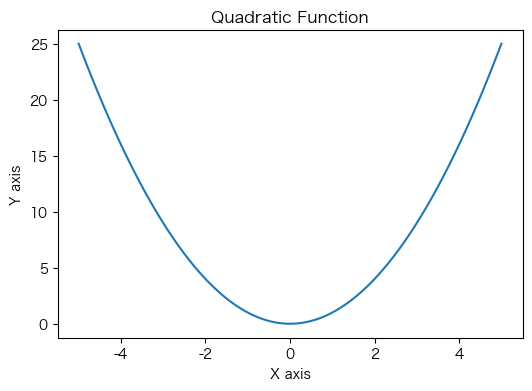

In [13]:
# 课件 P2 第一段：标题 + 轴标签（补上「先画数据」这一步）
x = np.linspace(-5, 5, 100)

plt.figure(figsize=(6, 4))         # 开一块 6x4 英寸的画布
plt.plot(x, x**2)                  # 先画线 —— 课件片段里没有这行，但没有它就没有图可标

plt.title('Quadratic Function')    # 整张图的标题
plt.xlabel('X axis')               # 横轴标签
plt.ylabel('Y axis')               # 纵轴标签
plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `x = np.linspace(-5, 5, 100)` | 造横坐标，和 §1.2 一样 |
| 4 | `plt.figure(figsize=(6, 4))` | 开画布。`figsize=(宽, 高)`，**单位是英寸** |
| 5 | `plt.plot(x, x**2)` | 画线。到这里图已经有了，只是还没「说明」 |
| 7 | `plt.title('Quadratic Function')` | ⚠️ 加的是 **Axes 的标题**（坐标区上方那行字），不是整个 Figure 的标题。要整个画布的标题得用 `fig.suptitle()` |
| 8-9 | `plt.xlabel('X axis')` / `plt.ylabel('Y axis')` | 横轴、纵轴标签。**里面的字符串是你自己定的**，写中文也行（`plt.xlabel('横坐标')` 完全没问题） |

> 💡 **为什么 `plt.title` 就能加上去？** 因为 `pyplot` 是「状态机」：`plt.plot` 会记住「当前坐标区」是哪个，后面的 `plt.title` 就往同一个坐标区上加。这正是它方便、但也容易出错的原因 —— 一旦有多个子图，你就分不清「当前」是哪个了。所以上一格我用 `ax.set_title()`，多用几次你就会偏向 `ax.` 系列。

## §2.2 图尺寸 `figsize`

课件的 `plt.figure(figsize=(10, 6))` 单独成段。这里把「英寸 ↔ 像素」的关系算清楚，以后调图不用猜。

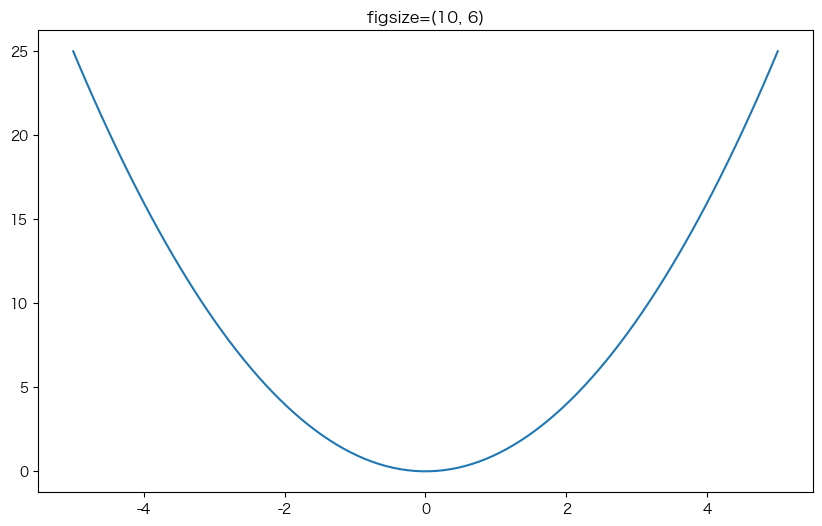

figsize=(10, 6) 配默认 dpi -> 1000 x 600 像素
当前默认 dpi      = 100.0
当前默认 figsize  = [6.4, 4.8]

换算公式：像素 = 英寸 x dpi


In [14]:
# 课件 P2 第二段：figsize
plt.figure(figsize=(10, 6))        # 10 英寸宽、6 英寸高
plt.plot(x, x**2)
plt.title('figsize=(10, 6)')
plt.show()

print('figsize=(10, 6) 配默认 dpi ->', 10 * 100, 'x', 6 * 100, '像素')
print('当前默认 dpi      =', plt.rcParams['figure.dpi'])
print('当前默认 figsize  =', plt.rcParams['figure.figsize'])
print()
print('换算公式：像素 = 英寸 x dpi')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `plt.figure(figsize=(10, 6))` | 开一块 10x6 英寸的画布。**必须在画数据之前调用** —— 在 `plot` 之后再 `figure` 会另开一张新图，原来那张就孤立了 |
| 7-9 | `plt.rcParams['figure.dpi']` | `rcParams` 是 matplotlib 的**全局配置字典**，`'figure.dpi'` 是「每英寸多少像素」。默认 100 |
| 11 | 换算公式 | `像素 = 英寸 × dpi`。10 英寸 × 100 dpi = 1000 像素宽 |

> ⚠️ **`figsize` 的坑：它不是像素**。想「生成一张 1920x1080 的图」，正确写法是
> ```python
> plt.figure(figsize=(19.2, 10.8), dpi=100)
> ```
> 而不是 `figsize=(1920, 1080)` —— 后者会生成一张 192000x108000 像素的巨图，多半直接把内存吃爆。
>
> 💡 交报告时常用的搭配：`figsize=(10, 6)` + `dpi=150`（清晰度和体积的平衡点）。

## §2.3 两条曲线 + 图例

这是课件 P2 里最重要的一段 —— 也是**课件截图和它自己的代码对不上的那一段**（下面 📌 勘误 3 细说）。

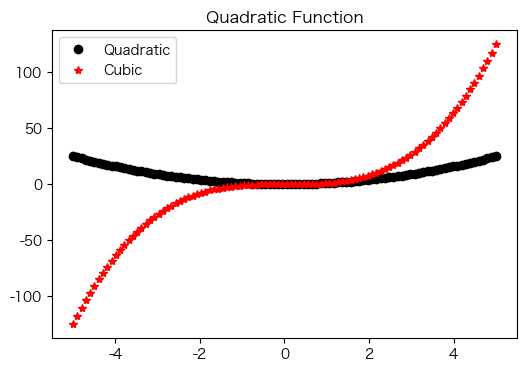

每条曲线画了 100 个点
所以 marker 会密到连成一条粗带子，而不是一颗颗分开的点


In [15]:
# 课件 P2 第三段：多条曲线 + 图例
x = np.linspace(-5, 5, 100)

plt.figure(figsize=(6, 4))
plt.plot(x, x**2, 'ko', label='Quadratic')     # 黑(k)色 圆圈(o)标记
plt.plot(x, x**3, 'r*', label='Cubic')         # 红(r)色 星号(*)标记
plt.legend(loc=2)                              # 显示图例，loc=2 表示左上角
plt.title('Quadratic Function')
plt.show()

print('每条曲线画了', x.size, '个点')
print('所以 marker 会密到连成一条粗带子，而不是一颗颗分开的点')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `x = np.linspace(-5, 5, 100)` | 100 个点 |
| 5 | `plt.plot(x, x**2, 'ko', label='Quadratic')` | `'ko'` = blac**k** + circle。**`label=` 里的名字，就是图例上显示的文字** —— 不写 `label`，`legend()` 就不知道标什么 |
| 6 | `plt.plot(x, x**3, 'r*', label='Cubic')` | `'r*'` = **r**ed + 星号。注意 `x**3` 里负数立方是负数，所以左边那半条会掉到 -100 以下 |
| 7 | `plt.legend(loc=2)` | 把带 `label` 的曲线收集起来，画一个图例框。`loc=2` 是**位置编号**，见下表 |
| 8 | `plt.title('Quadratic Function')` | ⚠️ 标题只写了 Quadratic，但图上画了 quadratic 和 cubic 两条 —— 这条标题是课件原文照抄，**它本身就不太合适** |

**`loc` 的编号规则**（不用背，记住「1 右上、2 左上、3 左下、4 右下」就够用）：

| `loc` 值 | 位置 | | `loc` 值 | 位置 |
|---|---|---|---|---|
| `0` | 自动挑（best） | | `6` | 右中 |
| `1` | 右上 | | `7` | 右中 |
| `2` | **左上**（课件用的） | | `8` | 中下 |
| `3` | 左下 | | `9` | 中上 |
| `4` | 右下 | | `10` | 正中 |
| `5` | 右中 | | `'best'` | 自动避开数据 |

> 💡 更直观的写法是直接给字符串：`plt.legend(loc='upper left')` ≡ `plt.legend(loc=2)`。**推荐用字符串**，三个月后你还看得懂。
>
> ⚠️ 想让图例出现，`label=` 必须在 `legend()` **之前**写在同一批 `plot` 上。顺序反了，图例就是个空框。

### 📌 勘误 3（P2）：课件那张截图，不是这段代码画出来的

把课件 P2 右下角的截图和上面这张图对照着看，有两处对不上：

| 对比项 | 课件截图 | 课件代码跑出来 |
|---|---|---|
| **图标题** | `Plot of Various Polynomials from -5.0 to 5.0` | `Quadratic Function` |
| **marker 密度** | 黑色圆圈的点**稀疏可数**（每条约 5~6 个） | 100 个 marker 密到连成一条粗带子 |
| **曲线的「胖瘦」** | 两条曲线几乎贴在一起，只在两端分开一点 | x³ 明显更陡，两端冲到 ±125 |

**原因很清楚**：`np.linspace(-5, 5, 100)` 是 **100 个点**，100 个 marker 挤在 6 英寸宽的图上，必然糊成一条带。截图里那种「稀疏 marker」的效果，只可能来自「点数很少」。

> 📌 **勘误 3（P2）**：课件 P2 的插图与它配的代码**不是同一次运行的结果**（标题不同、数据点密度不同）。这类「图文不符」在课件里很常见。
>
> **对你的实际影响**：**照抄课件的代码，得到的一定是上面那张「粗带子」图**，不要以为自己写错了。想让 marker 像截图那样稀疏，把点数改小即可：
> ```python
> x = np.linspace(-5, 5, 12)     # 12 个点，marker 立刻能数清
> ```
>
> 💡 顺带一个实用判断：**点超过 30 个左右，就不该再用 marker 了** —— 要么去掉 marker（只画线），要么把 `markersize` 调小、用 `markevery` 隔几个点画一个：
> ```python
> plt.plot(x, x**2, 'k-', marker='o', markevery=10, label='Quadratic')
> ```
> `markevery=10` 的意思是「每 10 个数据点才画一个 marker」—— 线是密的、点是稀的，这才是截图想要的效果。

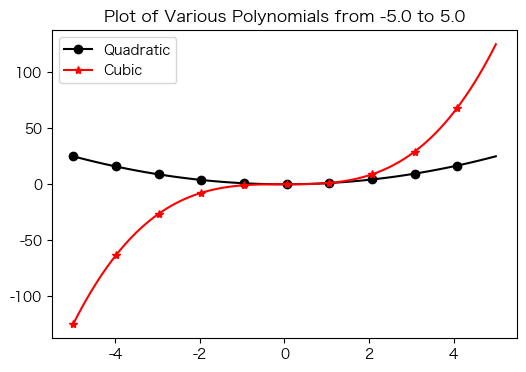

同样的 100 个点：线是连续曲线，marker 每 10 个点才画一个 -> 现在能数清了


In [16]:
# 🧪 还原课件截图的效果：线密、点稀
x = np.linspace(-5, 5, 100)

plt.figure(figsize=(6, 4))
plt.plot(x, x**2, 'k-', marker='o', markevery=10, label='Quadratic')
plt.plot(x, x**3, 'r-', marker='*', markevery=10, label='Cubic')
plt.legend(loc=2)
plt.title('Plot of Various Polynomials from -5.0 to 5.0')
plt.show()

print('同样的 100 个点：线是连续曲线，marker 每 10 个点才画一个 -> 现在能数清了')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 5 | `plt.plot(x, x**2, 'k-', marker='o', markevery=10, ...)` | 把风格字符串拆成三部分：`'k-'`（黑实线）+ `marker='o'`（圆圈）+ `markevery=10`（每 10 个点画一个标记） |
| 7 | `plt.title('Plot of Various Polynomials from -5.0 to 5.0')` | 用上课件截图里的标题 —— 这样两张图才真正可比 |
| 10 | `print(...)` | 说明关键点：**数据一点没变，变的只是「怎么画」** |

> 💡 `markevery` 还能接列表（`markevery=[0, 50, 99]` 只标首、中、尾）或者浮点数（`markevery=0.1` 表示每 10% 标一个）。画实验数据时非常有用。

## §2.4 📌 全局样式：课件那句 `seaborn-poster` 现在已经跑不通了

课件原文：

> Styles, such as seaborn and ggplot, can be applied globally with `plt.style.use('seaborn-poster')`.

这句话在**老版本 matplotlib 上是对的**。但从 **3.6 版**开始，matplotlib 把所有 `seaborn-*` 样式**改名**了（加上了 `v0_8` 前缀），旧名字直接被删掉。直接抄课件的写法，会得到 `OSError`。

跑一下就知道：

In [17]:
# 课件 P2 第四段：plt.style.use('seaborn-poster')  —— 实测
import matplotlib
import matplotlib.pyplot as plt

try:
    plt.style.use('seaborn-poster')          # 课件写法
    print('成功：seaborn-poster 可用')
except OSError as e:
    print('❌ 失败：', type(e).__name__)
    print('   ', str(e)[:150])
    print()

print('当前 matplotlib 版本：', matplotlib.__version__)
print()
print('这个版本里所有带 seaborn 的样式名：')
for s in [n for n in plt.style.available if 'seaborn' in n]:
    print('   ', s)

❌ 失败： OSError
    'seaborn-poster' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.avail

当前 matplotlib 版本： 3.10.6

这个版本里所有带 seaborn 的样式名：
    seaborn-v0_8
    seaborn-v0_8-bright
    seaborn-v0_8-colorblind
    seaborn-v0_8-dark
    seaborn-v0_8-dark-palette
    seaborn-v0_8-darkgrid
    seaborn-v0_8-deep
    seaborn-v0_8-muted
    seaborn-v0_8-notebook
    seaborn-v0_8-paper
    seaborn-v0_8-pastel
    seaborn-v0_8-poster
    seaborn-v0_8-talk
    seaborn-v0_8-ticks
    seaborn-v0_8-white
    seaborn-v0_8-whitegrid


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 5 | `try:` | 「试着执行，出事别崩」 |
| 6 | `plt.style.use('seaborn-poster')` | **课件的原话**。在当前版本上会抛异常 |
| 8 | `except OSError as e:` | 捕获 `OSError`。⚠️ 这里**必须写 OSError**：样式名找不到时 matplotlib 抛的就是它，不是 `KeyError` 也不是 `ValueError` |
| 14 | `plt.style.available` | 一个列表，装着当前版本**所有**能用的样式名 |
| 15 | `[n for n in ... if 'seaborn' in n]` | 列表推导式，过滤出带 `seaborn` 的。你会看到它们全都叫 `seaborn-v0_8-xxx` |

**输出会告诉你两件事**：旧名字 `seaborn-poster` 已经不在表里；新名字是 `seaborn-v0_8-poster`。

> 📌 **勘误 2（P2）**：`plt.style.use('seaborn-poster')` 在 matplotlib ≥ 3.6 上会直接报错：
> ```
> OSError: 'seaborn-poster' is not a valid package style, path of style file,
> URL of style file, or library style name
> ```
> **正确写法**：把名字换掉 ——
> ```python
> plt.style.use('seaborn-v0_8-poster')     # 老样式的现代名字
> plt.style.use('ggplot')                  # ggplot 风格，名字没变，课件这句仍然有效
> plt.style.use('default')                 # 恢复默认，别把后面所有图都染色了
> ```
> `v0_8` 里的 `0_8` 指的是「seaborn 0.8 时代的样式」，matplotlib 把它们冻结下来、和 seaborn 本体解耦，所以名字里带了个版本号。
>
> 💡 **`style.use` 是全局的**：一旦调用，**后面所有图**都变风格。所以临时换风格要记得换回来，否则你会对着「为什么这张图突然变灰底了」发呆半天。

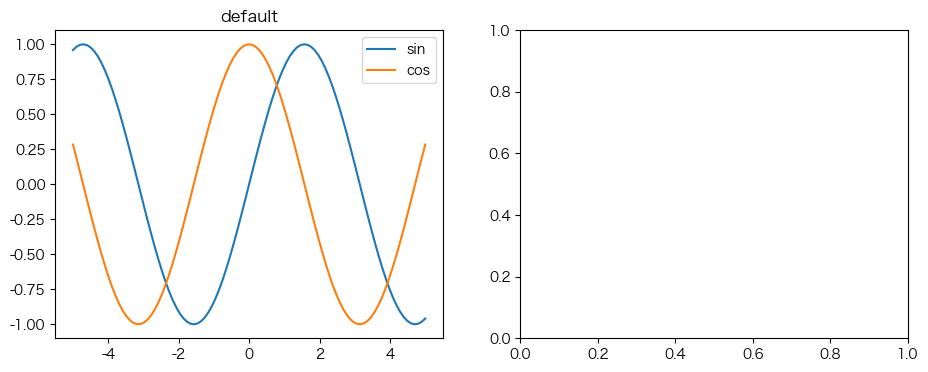

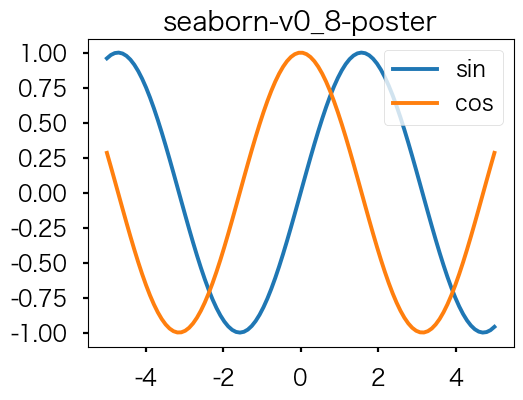

已恢复默认样式


In [18]:
# 🧪 换上新名字，看看到底变了什么
plt.style.use('default')                     # 先回到默认，保证下面看到的差异是真实的

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 左：默认样式
axes[0].plot(x, np.sin(x), label='sin')
axes[0].plot(x, np.cos(x), label='cos')
axes[0].set_title('default')
axes[0].legend()

# 右：课件想要的 poster 样式（新名字）
plt.style.use('seaborn-v0_8-poster')
fig2, ax2 = plt.subplots(figsize=(5.5, 4))
ax2.plot(x, np.sin(x), label='sin')
ax2.plot(x, np.cos(x), label='cos')
ax2.set_title('seaborn-v0_8-poster')
ax2.legend()

plt.style.use('default')                     # ⚠️ 换回来！否则本章后面所有图都变样
use_cjk_font()                               # ⚠️ style.use 会重置 rcParams，中文字体得重新装回来
plt.show()

print('已恢复默认样式')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `plt.style.use('default')` | 明确回到默认风格。**开局第一步就复位**，能避免「上一个格子留下的样式污染这一个格子」 |
| 4 | `fig, axes = plt.subplots(1, 2, figsize=(11, 4))` | 建 1 行 2 列两个坐标区。左边这个用的是默认样式 |
| 15 | `plt.style.use('seaborn-v0_8-poster')` | ⚠️ 样式**只影响之后新建的图** —— 左边那张已经画好了，不会被改（但整个 Figure 的默认配色会变） |
| 16 | `fig2, ax2 = plt.subplots(figsize=(5.5, 4))` | 新开一块画布。这时 `seaborn-v0_8-poster` 才生效：灰底、白网格、字号偏大 |
| 23 | `plt.style.use('default')` | **复位**。这行是这一格最重要的代码 —— 没有它，本章从第 3 节开始的每一张图都会是灰底大字的 poster 风格 |
| 24 | `use_cjk_font()` | ⚠️ **这一行是踩过坑才加上的**：`style.use` 把 `rcParams` 整个重置，中文字体会一起丢。不补这一句，§3 之后所有图里的中文都会变成方框 |

> 💡 只想让**一个格子**用特殊样式，又不想影响全章？用上下文管理器：
> ```python
> with plt.style.context('seaborn-v0_8-poster'):
>     plt.figure(); plt.plot(x, x**2); plt.show()
> # 出了 with 块，样式自动还原
> ```
> 这是比「用了再手动改回来」更安全的做法。
>
> ⚠️ **`plt.style.use()` 会重置整个 `rcParams`** —— 这是它最坑的地方。两件事会跟着丢：
> 1. 你手动改过的默认值（比如 `plt.rcParams['figure.figsize'] = (10, 6)`）；
> 2. **§0 里设好的中文字体** —— 于是图里的中文会从某一格开始突然全变方框。
>
> 这就是上面那一格结尾为什么要补一句 `use_cjk_font()`。**凡是用了 `style.use`，后面都要补一次。**

---
# §3 · 3D 线图（3D Plotting with Matplotlib）

## 课件原文（P3）

- **Matplotlib** is a powerful plotting library in Python. To plot 3D figures, the `mplot3d` toolkit must be imported and axes defined (`ax = plt.axes(projection='3d')` commonly).
- The 3D plot functionalities include:
  - Line plots using `plot3D()`.
  - Scatter plots using `scatter()`.
  - Surface plots using `plot_surface()`.

**Example 1: 3D Line Plot**

- **Goal**: Create a 3D line plot using parametric data.
- **Key Code**:

```python
import numpy as np
from mpl_toolkits import mplot3d
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection='3d')
t = np.arange(0, 10*np.pi, np.pi/50)
x = np.sin(t)
y = np.cos(t)
ax.plot3D(x, y, t)
ax.set_title('3D Parametric Plot')
plt.show()
```

- **Result**: A 3D parametric plot of `(x, y, t)`, with grid and axis labels enabled.

## 人话版

- 想画 3D，要做两件事：**导入 `mplot3d`**（注册 3D 能力）+ **建一个 `projection='3d'` 的坐标区**
- 3D 下也是三种图，和 2D 一一对应：

| 2D 里叫 | 3D 里叫 | 画什么 |
|---|---|---|
| `plot()` | `plot3D()` | 线（一条空间曲线） |
| `scatter()` | `scatter()` | 点（一团空间点云） |
| — | `plot_surface()` | 面（一张曲面，2D 没有对应物） |

- 课件这个例子的数据是**参数方程**：`t` 是参数，`x``y` 都由 `t` 算出来。这是 3D 曲线最自然的描述方式 —— 因为一条空间曲线本来就是一个点随参数 `t` 移动的轨迹

## §3.1 课件原码跑一遍

⚠️ 这一格是**整段照抄课件**（连 `figsize=(10,10)` 都没改）。

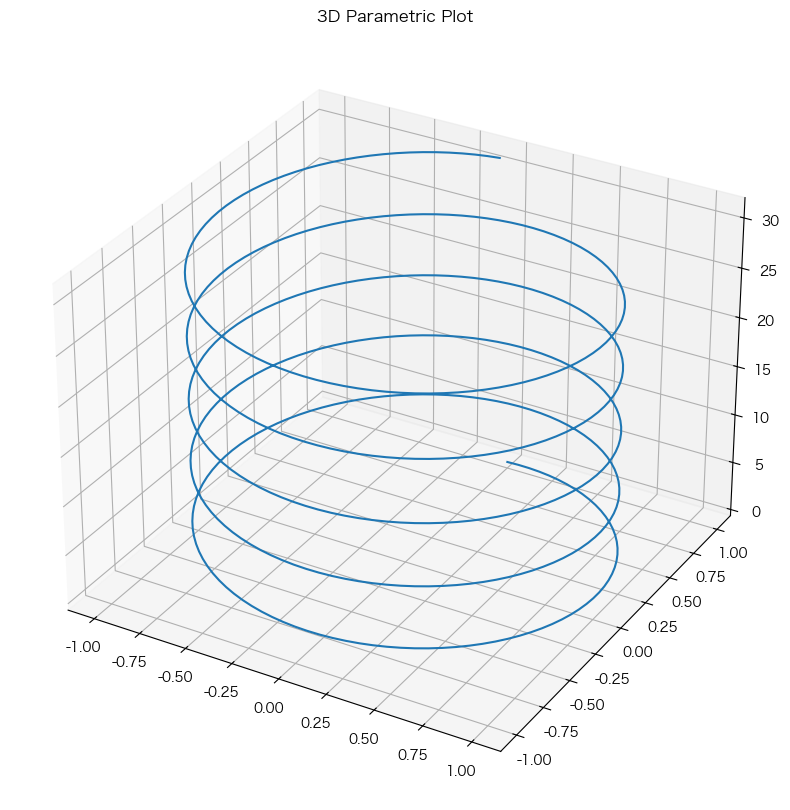

In [19]:
# 课件 P3：3D 螺旋线（原样照抄）
import numpy as np
from mpl_toolkits import mplot3d
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection='3d')
t = np.arange(0, 10*np.pi, np.pi/50)
x = np.sin(t)
y = np.cos(t)
ax.plot3D(x, y, t)
ax.set_title('3D Parametric Plot')
plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `import numpy as np` | 造数据 |
| 3 | `from mpl_toolkits import mplot3d` | 3D 工具箱。⚠️ 这一行**看起来什么都没做**（`mplot3d` 后面一次都没用到），但**不能删** —— 它的作用是「注册 3D 投影」。在新版 matplotlib 里 `projection='3d'` 通常已经自动可用，但写上是最保险的老习惯 |
| 6 | `fig = plt.figure(figsize=(10,10))` | 开一块 **10x10 英寸的正方形画布**。3D 图用正方形比较好看，因为三个轴要匀称 |
| 7 | `ax = plt.axes(projection='3d')` | **关键的一行**。`plt.axes()` 在**当前画布**上铺一个坐标区，`projection='3d'` 告诉它「要三维的」。返回的 `ax` 就是这块 3D 坐标区 |
| 8 | `t = np.arange(0, 10*np.pi, np.pi/50)` | 参数 `t`：从 0 开始，每次加 `π/50`，一直到 `10π` 之前。**`arange` 不含终点**，所以 `10π` 取不到 |
| 9-10 | `x = np.sin(t)` / `y = np.cos(t)` | 逐元素求正弦余弦。`t` 有 500 个数，`x``y` 也各有 500 个 |
| 11 | `ax.plot3D(x, y, t)` | 画空间曲线。**三个数组对应三个轴**：先 `x`、再 `y`、最后 `t`（做竖直轴） |
| 12 | `ax.set_title('3D Parametric Plot')` | 加标题。3D 坐标区同样有 `set_title` |
| 13 | `plt.show()` | 渲染 |

> 💡 **`ax.plot3D` 和 `ax.plot` 其实是同一个函数**（`plot3D` 只是个别名）。给 2 个数组它画 2D，给 3 个就画 3D。课件用 `plot3D` 是为了强调「这是三维的」，可读性更好。
>
> ⚠️ **`plt.axes()` vs `plt.subplots()`**：`plt.axes()` 是「在现有画布上铺一层坐标区」。如果你前面已经 `plt.plot(...)` 画过东西，再 `plt.axes()` 会**叠一层上去**，两张图会重叠。这也是 §6 要讲的 📌 勘误 4。

## §3.2 🧪 这条线到底是什么？把参数方程摊开看

课件只说「parametric data」。但看图之前最好先知道**为什么它长成一根弹簧**。

In [20]:
# 🧪 把 (x, y, t) 摊开成一张表
print('t 的个数：', t.size)
print('t 的范围：', t.min(), '->', round(float(t.max()), 4), '  （10*pi 约等于 31.4159）')
print('t 的步长：', round(float(t[1] - t[0]), 6), '  （就是 pi/50）')
print()
print('   t        x=sin(t)   y=cos(t)     空间点 (x, y, t)')
for i in [0, 25, 50, 100, 250]:
    print('%8.3f   %8.3f   %8.3f     (%.3f, %.3f, %.3f)'
          % (t[i], np.sin(t[i]), np.cos(t[i]), np.sin(t[i]), np.cos(t[i]), t[i]))
print()
print('两个关键事实：')
print('  1. x=sin(t), y=cos(t)  =>  x^2 + y^2 恒等于 1')
print('     实测 np.allclose(x**2 + y**2, 1.0) =', np.allclose(x**2 + y**2, 1.0))
print('     也就是说：不管 t 走到哪，水平面上永远待在一个半径为 1 的圆上')
print('  2. 竖直坐标就是 t 本身，一直单调上升')
print('     两者合起来 = 一边绕圈、一边升高 = 螺旋线（helix）')
print()
print('总圈数 = 10*pi / (2*pi) =', round(float(t.max() / (2 * np.pi)), 2), '圈')
print('顶点数 =', t.size, '（t 每走 pi/50 画一个点，一圈 100 个点）')

t 的个数： 500
t 的范围： 0.0 -> 31.3531   （10*pi 约等于 31.4159）
t 的步长： 0.062832   （就是 pi/50）

   t        x=sin(t)   y=cos(t)     空间点 (x, y, t)
   0.000      0.000      1.000     (0.000, 1.000, 0.000)
   1.571      1.000     -0.000     (1.000, -0.000, 1.571)
   3.142     -0.000     -1.000     (-0.000, -1.000, 3.142)
   6.283      0.000      1.000     (0.000, 1.000, 6.283)
  15.708     -0.000     -1.000     (-0.000, -1.000, 15.708)

两个关键事实：
  1. x=sin(t), y=cos(t)  =>  x^2 + y^2 恒等于 1
     实测 np.allclose(x**2 + y**2, 1.0) = True
     也就是说：不管 t 走到哪，水平面上永远待在一个半径为 1 的圆上
  2. 竖直坐标就是 t 本身，一直单调上升
     两者合起来 = 一边绕圈、一边升高 = 螺旋线（helix）

总圈数 = 10*pi / (2*pi) = 4.99 圈
顶点数 = 500 （t 每走 pi/50 画一个点，一圈 100 个点）


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-4 | `t.size` / `t.min()` / `t.max()` | 数组的三个基本体检项：**几个数、最小多少、最大多少**。画图前先看这三个，能避免 90% 的「图怎么是空的」 |
| 3 | `round(float(t.max()), 4)` | ⚠️ 为什么要套一层 `float()`？因为 numpy 的标量直接 `round` 出来的格式在不同版本里略有差别，转成 Python 原生 `float` 最稳 |
| 6-8 | `for i in [0, 25, 50, 100, 250]:` | 抽几个点打印。**画图前先打印几个数**，是排查问题的第一手段 |
| 11 | `np.allclose(x**2 + y**2, 1.0)` | `allclose` = 「全部足够接近」。因为浮点数算 `sin²+cos²` 不会**精确**等于 1，只会等于 `0.9999999999999999` 这种，所以不能用 `==` |

**结论**：`x = sin(t), y = cos(t)` 是「在单位圆上匀速转圈」，`z = t` 是「匀速升高」。两件事同时发生 → **螺旋线**。

> 💡 这就是「参数方程」的威力：**用第三个变量 `t` 当导演，同时指挥 `x``y``z` 三个坐标**。直接写「螺旋线」的方程很难，但写成 `(sin t, cos t, t)` 就一目了然。
>
> ⚠️ **`np.allclose` 是浮点数世界的 `==`**。以后比较两个浮点结果，都用 `allclose`（数组）或 `math.isclose`（单个数），别用 `==`。

## §3.3 🧪 换个角度看同一条线

3D 图有个 2D 没有的问题：**同一份数据，换个视角就是另一张图**。课件那张图用的是 matplotlib 的默认视角，我们对比三个。

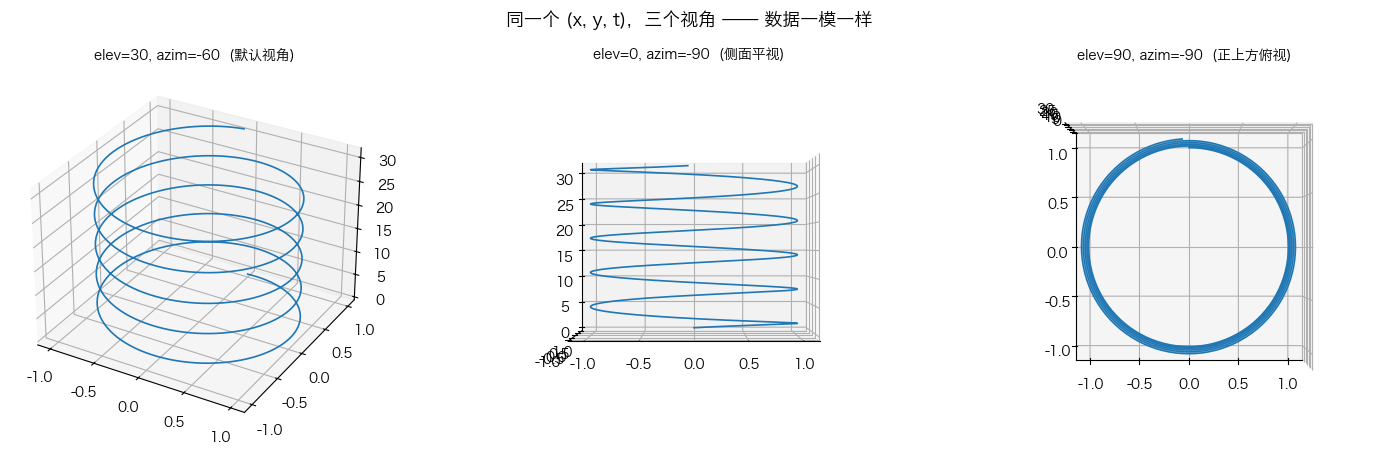

elev = 仰角（抬头多少度），azim = 方位角（绕 z 轴转到哪）
默认是 elev=30, azim=-60，也就是课件那张图的样子


In [21]:
# 🧪 同一条螺旋线，三个视角
views = [(30, -60), (0, -90), (90, -90)]
titles = ['elev=30, azim=-60  (默认视角)', 'elev=0, azim=-90  (侧面平视)', 'elev=90, azim=-90  (正上方俯视)']

fig = plt.figure(figsize=(15, 4.5))
for k, ((elev, azim), title) in enumerate(zip(views, titles), start=1):
    ax = fig.add_subplot(1, 3, k, projection='3d')
    ax.plot3D(x, y, t, linewidth=1.2)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(title, fontsize=10)

fig.suptitle('同一个 (x, y, t)，三个视角 —— 数据一模一样', fontsize=13)
plt.tight_layout()
plt.show()

print('elev = 仰角（抬头多少度），azim = 方位角（绕 z 轴转到哪）')
print('默认是 elev=30, azim=-60，也就是课件那张图的样子')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-3 | `views` / `titles` | 把三组视角参数和对应说明配成两张表，循环时一一取用 |
| 6 | `fig.add_subplot(1, 3, k, projection='3d')` | **另一种建坐标区的方式**：`(行, 列, 第几个)`。和 `plt.subplots(1, 3)` 效果类似，但可以在循环里一个个加，且能带 `projection=` |
| 7 | `ax.plot3D(x, y, t, linewidth=1.2)` | 复用上面的 `x``y``t` —— **数据一个没变** |
| 8 | `ax.view_init(elev=elev, azim=azim)` | 设置视角。`elev` 是仰角（0=平视，90=从正上方看），`azim` 是方位角 |
| 15 | `print(...)` | 把这两个参数的含义写出来 |

**三张图说明了什么**：

| 视角 | 看到的样子 | 为什么 |
|---|---|---|
| `elev=30, azim=-60` | 一根立体的弹簧 | 默认视角，兼顾三个轴（**课件的图就是这个**） |
| `elev=0, azim=-90` | 看起来像一条正弦波 | 平视时 `y` 轴被压扁，只剩 `x` 和 `t` 两个维度可见 |
| `elev=90, azim=-90` | 一个正圆 | 从正上方看，`x=sin t``y=cos t` 在单位圆上转圈，`t` 的信息完全丢失 |

> ⚠️ **这是 3D 图最重要的一个坑**：**同一份数据，换个视角能讲出完全不同的故事**。所以 3D 图**永远要标清坐标轴标签**，而且关键结论最好额外配一张 2D 投影图（比如上面第 2、3 张）来佐证。
>
> 💡 交互式环境下（`%matplotlib widget`）你可以**用鼠标拖着转**，那样找视角最快，找到满意的角度后再把 `elev` / `azim` 抄进代码里。

---
# §4 · 3D 曲面与散点（Surface and Scatter Plotting in 3D）

## 课件原文（P4）

**3D Surface Plot**

- **Purpose**: To visualize functions of two variables `Z = f(X, Y)`, where `X` and `Y` are generated from `np.meshgrid()`.
- **Steps**:
  1. Create a meshgrid using lists/arrays for `X` and `Y`.
  2. Compute `Z` values using the function `Z = sin(X) * cos(Y)`.
  3. Plot the surface with `plot_surface()`, using a colormap (e.g., `plt.cm.cividis`).
- **Key Code**:

```python
x = np.arange(-5, 5.1, 0.2)
y = np.arange(-5, 5.1, 0.2)
X, Y = np.meshgrid(x, y)
Z = np.sin(X)*np.cos(Y)
ax.plot_surface(X, Y, Z, cmap=plt.cm.cividis)
plt.show()
```

**3D Scatter Plot**

- **Goal**: Create a 3D scatter plot with randomly generated data.
- **Key Code**:

```python
x = np.random.random(50)
y = np.random.random(50)
z = np.random.random(50)
ax.scatter(x, y, z, c='r', s=50)
plt.show()
```

## 人话版

- **曲面图干什么用**：一个函数有两个自变量，`Z = f(X, Y)`。这种关系在 2D 图上画不出来（要三个轴），3D 曲面正好
- **`np.meshgrid()` 干什么用**：把「一排 x」和「一排 y」，展开成「所有 (x, y) 组合」的两张表格，这样 `sin(X)*cos(Y)` 才能逐点算
- **`plot_surface()`**：把这张表格画成一张曲面，`cmap=` 决定颜色怎么映射到高度
- **散点图**：`ax.scatter(x, y, z, c='r', s=50)` —— `c` 是颜色，`s` 是点的大小（size）

## §4.1 🧪 先搞懂 `meshgrid`（这是本节唯一的难点）

`meshgrid` 是 3D 曲面图的门槛。用最小的例子（3 个 x、2 个 y）一次看清楚。

In [22]:
# 🧪 meshgrid 到底做了什么？用 3x2 的最小例子
x_small = np.array([0, 1, 2])
y_small = np.array([10, 20])

X, Y = np.meshgrid(x_small, y_small)

print('x_small =', x_small, '  （3 个数）')
print('y_small =', y_small, '  （2 个数）')
print()
print('meshgrid 之后：')
print('X ='); print(X)
print('Y ='); print(Y)
print()
print('X 的形状 =', X.shape, '，Y 的形状 =', Y.shape)
print()
print('把每个位置摊开看：')
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        print('   位置[%d,%d]:  x = %-3d  y = %-3d  ->  网格点 (%d, %d)'
              % (i, j, X[i, j], Y[i, j], X[i, j], Y[i, j]))
print()
print('一句话总结：3 个 x 和 2 个 y 一共能配出 3x2 = 6 个点，')
print('           meshgrid 把这 6 个点摆成两张同形状的表：X 表放横坐标，Y 表放纵坐标。')

x_small = [0 1 2]   （3 个数）
y_small = [10 20]   （2 个数）

meshgrid 之后：
X =
[[0 1 2]
 [0 1 2]]
Y =
[[10 10 10]
 [20 20 20]]

X 的形状 = (2, 3) ，Y 的形状 = (2, 3)

把每个位置摊开看：
   位置[0,0]:  x = 0    y = 10   ->  网格点 (0, 10)
   位置[0,1]:  x = 1    y = 10   ->  网格点 (1, 10)
   位置[0,2]:  x = 2    y = 10   ->  网格点 (2, 10)
   位置[1,0]:  x = 0    y = 20   ->  网格点 (0, 20)
   位置[1,1]:  x = 1    y = 20   ->  网格点 (1, 20)
   位置[1,2]:  x = 2    y = 20   ->  网格点 (2, 20)

一句话总结：3 个 x 和 2 个 y 一共能配出 3x2 = 6 个点，
           meshgrid 把这 6 个点摆成两张同形状的表：X 表放横坐标，Y 表放纵坐标。


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-3 | `x_small = np.array([0, 1, 2])` | 故意只用 3 个数，这样能整个打印出来看 |
| 5 | `X, Y = np.meshgrid(x_small, y_small)` | **核心一行**。返回两个**同形状**的二维数组 |
| 9-10 | `print(X)` / `print(Y)` | 看输出：`X` 的每一**行**都是 `[0 1 2]`（横向复制），`Y` 的每一**列**都是 `[10 20]` 转置后的样子（纵向复制） |
| 15-17 | 双重循环打印 | 把 6 个网格点逐一列出来，确认「所有组合都配到了」 |

**为什么需要它？** 因为 `np.sin(X)` 要求 `X` 是个数组，逐元素算。而函数 `f(x, y)` 有两个自变量 —— `meshgrid` 就是把「两个自变量的所有组合」铺成两张表，让 numpy 能做逐元素运算。

> ⚠️ **`meshgrid` 的参数顺序很容易记反**：`np.meshgrid(x, y)` 返回 `X, Y` —— **第一个参数产出的数组放第一个**。
>
> ⚠️ **形状要一致**：`X``Y``Z` 三个数组必须同形状，否则 `plot_surface` 会报错。画图前 `print(Z.shape)` 是个好习惯。
>
> 💡 老代码里偶尔会看到 `np.meshgrid(x, y, sparse=True)` 或 `indexing='ij'`。**默认是 `indexing='xy'`**（和我们平时的 (x, y) 顺序一致），课件用的就是默认值，不用管。

## §4.2 课件原码：3D 曲面

⚠️ 注意：课件这段**只有 5 行**，缺了「建 `fig` 和 `ax`」那一步 —— 见下面的 📌 勘误 4。

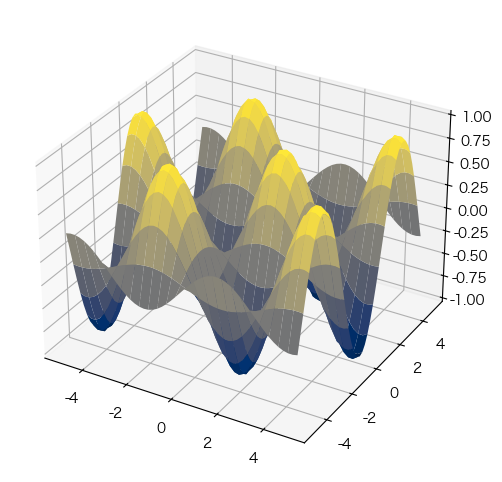

x 有 51 个点，y 有 51 个点
Z 的形状 = (51, 51)  -> 一共 2601 个网格点
Z 的取值范围：-1.000 ~ 1.000   （sin*cos 的乘积必然落在 [-1, 1]）


In [23]:
# 课件 P4 上段：3D 曲面
# ⚠️ 课件只给了后面几行，前面这两行必须自己补（见 📌 勘误 4）
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')

x = np.arange(-5, 5.1, 0.2)
y = np.arange(-5, 5.1, 0.2)
X, Y = np.meshgrid(x, y)
Z = np.sin(X)*np.cos(Y)
ax.plot_surface(X, Y, Z, cmap=plt.cm.cividis)
plt.show()

print('x 有', x.size, '个点，y 有', y.size, '个点')
print('Z 的形状 =', Z.shape, ' -> 一共', Z.size, '个网格点')
print('Z 的取值范围：%.3f ~ %.3f   （sin*cos 的乘积必然落在 [-1, 1]）' % (Z.min(), Z.max()))

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 3 | `fig = plt.figure(figsize=(8, 6))` | 开画布。**课件里没有这行** |
| 4 | `ax = plt.axes(projection='3d')` | 建 3D 坐标区。**课件里也没有这行**（它继承了上一页 P3 的 `ax`） |
| 6-7 | `np.arange(-5, 5.1, 0.2)` | 从 -5 到 5，**步长 0.2**。`5.1` 是故意的（`arange` 不含终点，写 5.0 就取不到 5.0） |
| 8 | `X, Y = np.meshgrid(x, y)` | 铺成 51x51 的网格 |
| 9 | `Z = np.sin(X)*np.cos(Y)` | 逐元素相乘。`*` 是**逐元素**乘，不是矩阵乘（矩阵乘要写 `@`） |
| 10 | `ax.plot_surface(X, Y, Z, cmap=plt.cm.cividis)` | 画曲面。`cmap` 决定「高度 → 颜色」的映射，`cividis` 是种对色盲友好的蓝黄配色 |
| 11 | `plt.show()` | 渲染 |

> 📌 **勘误 4（P4）**：课件的曲面代码**是个片段，不能单独运行**。它用到了 `ax`，但 `ax` 是在**上一页 P3** 里创建的。把这一页的 5 行单独抄下来跑，会得到：
> ```
> NameError: name 'ax' is not defined
> ```
> **正确做法**：每次画图都从头建一遍 `fig` 和 `ax`（本格最上面两行就是补的部分）。
>
> 💡 **为什么课件会这样写？** 因为 Keynote 一页放不下。但这也带来一个真实的坏习惯：**依赖上一格留下的 `ax`**。一旦你单独重跑某一格，就会炸。**能自洽的代码格才是好代码格。**
>
> ⚠️ 另外：`plt.cm.cividis` 这种写法（通过 `plt.cm`）目前仍然可用。更现代的等价写法是直接给字符串 `cmap='cividis'`，更短也更不容易出错。

## §4.3 课件原码：3D 散点

课件这段更短，同样缺 `fig`/`ax`。这次顺便把「随机数怎么才可复现」讲清楚。

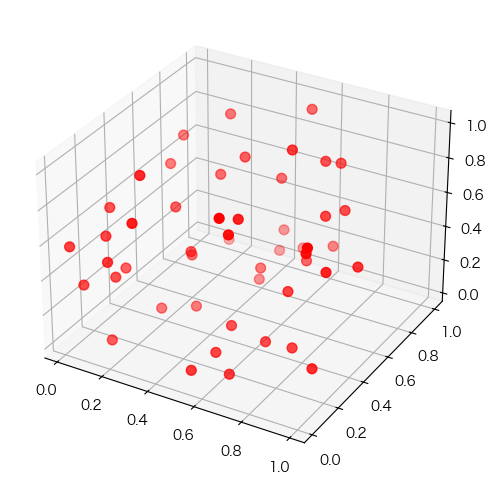

x y z 各 50 个数，范围都在 [0, 1)：
  x: 0.0156 ~ 0.9897
  y: 0.0136 ~ 0.9969
  z: 0.0201 ~ 0.9982

所以点云挤在一个 1x1x1 的立方体里 —— 这就是课件那张图的样子


In [24]:
# 课件 P4 下段：3D 散点
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection='3d')

x = np.random.random(50)
y = np.random.random(50)
z = np.random.random(50)
ax.scatter(x, y, z, c='r', s=50)
plt.show()

print('x y z 各 50 个数，范围都在 [0, 1)：')
print('  x: %.4f ~ %.4f' % (x.min(), x.max()))
print('  y: %.4f ~ %.4f' % (y.min(), y.max()))
print('  z: %.4f ~ %.4f' % (z.min(), z.max()))
print()
print('所以点云挤在一个 1x1x1 的立方体里 —— 这就是课件那张图的样子')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 3 | `ax.scatter(x, y, z, c='r', s=50)` | 3D 散点。三个数组分别对应三个轴。注意和 2D 的 `scatter(x, y)` 就差一个 `z` |
| 3 | `c='r'` | **c**olor，颜色。可以给单个颜色名，也可以给一组数（那时颜色会按数值映射，需要配 `cmap`） |
| 3 | `s=50` | **s**ize，点的面积（单位是点²，不是半径！）。默认 `s=36` 左右，`50` 稍微大一点 |
| 6-8 | `np.random.random(50)` | 生成 50 个 `[0, 1)` 之间的**均匀分布**随机数。⚠️ `[0, 1)` 是**左闭右开** —— 取得到 0，取不到 1 |
| 10-13 | `x.min()` / `x.max()` | 用实测数据说明「为什么点云是一个立方体」 |

> ⚠️ **`np.random.random` 是「老式」随机数接口**（属于 `RandomState` 那一套）。它**还能用**，但 numpy 从 1.17 起推荐新的 `Generator` 写法。两者最大的差别是**可复现性怎么控制**：

```python
# 老写法：用全局种子
np.random.seed(42)
a = np.random.random(3)
np.random.seed(42)
b = np.random.random(3)
# a 和 b 相同

# 新写法（推荐）：显式拿一个生成器
rng = np.random.default_rng(42)
c = rng.random(3)
```

> 下面的格子把这件事实测一遍。

In [25]:
# 🧪 随机数：可复现 vs 不可复现
print('--- 老写法：np.random.seed + np.random.random ---')
np.random.seed(42)
a = np.random.random(3)
np.random.seed(42)                 # 重新播一遍同样的种子
b = np.random.random(3)
print('第一次：', a)
print('第二次：', b)
print('两次相同？', np.allclose(a, b), ' <- 固定种子 = 结果可复现')
print()

print('--- 新写法：np.random.default_rng ---')
rng1 = np.random.default_rng(42)
c = rng1.random(3)
rng2 = np.random.default_rng(42)   # 同样的种子，新的生成器
d = rng2.random(3)
print('第一次：', c)
print('第二次：', d)
print('两次相同？', np.allclose(c, d), ' <- 同样可复现')
print()

print('注意 a 和 c 不一样：')
print('  老接口 seed(42) ->', a)
print('  新接口 default_rng(42) ->', c)
print('两套接口的随机数流是独立的，同一个种子不会给同样的数')

--- 老写法：np.random.seed + np.random.random ---
第一次： [0.37454012 0.95071431 0.73199394]
第二次： [0.37454012 0.95071431 0.73199394]
两次相同？ True  <- 固定种子 = 结果可复现

--- 新写法：np.random.default_rng ---
第一次： [0.77395605 0.43887844 0.85859792]
第二次： [0.77395605 0.43887844 0.85859792]
两次相同？ True  <- 同样可复现

注意 a 和 c 不一样：
  老接口 seed(42) -> [0.37454012 0.95071431 0.73199394]
  新接口 default_rng(42) -> [0.77395605 0.43887844 0.85859792]
两套接口的随机数流是独立的，同一个种子不会给同样的数


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-6 | `np.random.seed(42)` 然后 `np.random.random(3)` | 老接口：`seed` 设置**全局**随机种子，之后所有 `np.random.*` 都按这个种子往下走 |
| 8-9 | 再 `seed(42)` 再取一次 | 因为种子重置了，所以得到**一模一样**的三个数 |
| 14-17 | `rng1 = np.random.default_rng(42)` | 新接口：`default_rng(42)` 造一个**独立的随机数生成器对象**。它不碰全局状态 |
| 25-27 | 对比 `a` 和 `c` | ⚠️ 两套接口的算法不同，**同一个种子 42 得到的数不一样**。所以「用 42 就能复现别人的结果」这句话**只在同一套接口内成立** |

> 💡 **做实验一定要固定种子**。否则你调了半天参数，其实只是每次随机数据不同 —— 这种「假进步」非常浪费时间。写报告时也建议把种子写进图注。
>
> ⚠️ **不要在生产代码里用全局 `np.random.seed`**：它会影响整个程序里所有用到随机数的地方（包括你 import 的第三方库）。新代码请用 `default_rng`。

## §4.4 🧪 曲面图的三个常用增强

课件那张曲面有点「糙」：网格 0.2 步长的棱角看得见、没有颜色条、看不出高度。这三个增强最实用。

原网格 (51, 51) ->  新网格 (101, 101)


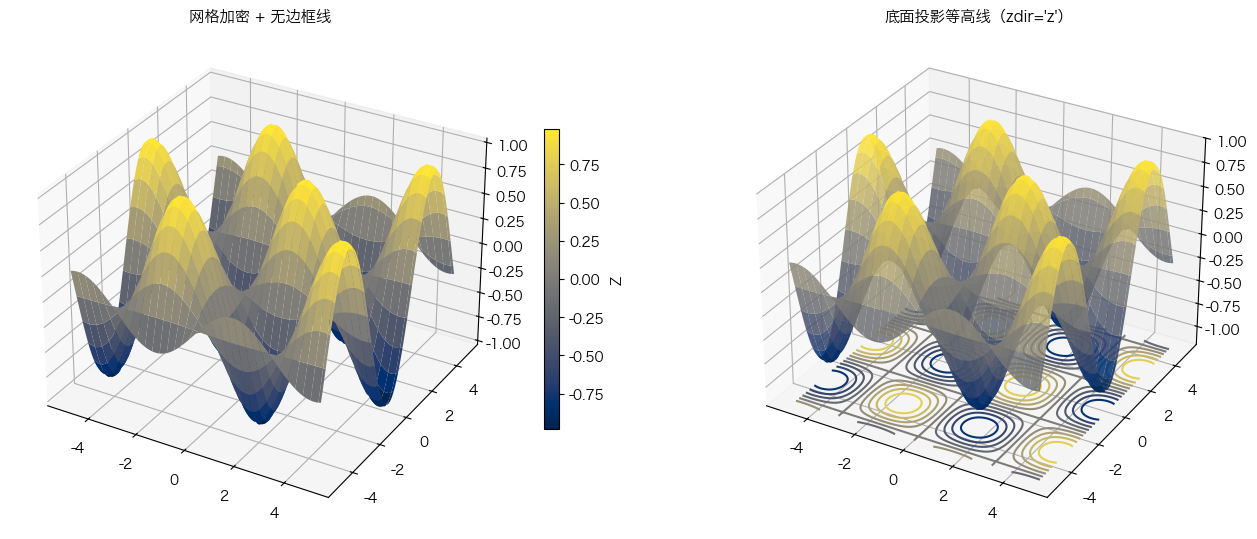


三个增强各自解决了什么：
  1) 步长 0.2 -> 0.1      ：曲面更光滑，棱角消失
  2) fig.colorbar(...)    ：加一根颜色条，读图的人才知道颜色对应多高
  3) ax.contour(offset=..)：把「俯视图」画在地板上，等于同时给了 3D + 2D 两个视角


In [26]:
# 🧪 网格加密 + 颜色条 + 底面等高线
fig = plt.figure(figsize=(14, 5.5))

x2 = np.arange(-5, 5.01, 0.1)          # 步长从 0.2 缩到 0.1，网格密一倍
y2 = np.arange(-5, 5.01, 0.1)
X2, Y2 = np.meshgrid(x2, y2)
Z2 = np.sin(X2) * np.cos(Y2)
print('原网格', Z.shape, '->  新网格', Z2.shape)

# 左：加密 + 去掉网格线 + 加颜色条
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X2, Y2, Z2, cmap='cividis', linewidth=0, antialiased=True)
ax1.set_title('网格加密 + 无边框线', fontsize=11)
fig.colorbar(surf, ax=ax1, shrink=0.6, label='Z')

# 右：把等高线投到「地板」上
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X2, Y2, Z2, cmap='cividis', alpha=0.85, linewidth=0)
ax2.contour(X2, Y2, Z2, zdir='z', offset=-1.2, cmap='cividis', levels=12)
ax2.set_zlim(-1.2, 1)
ax2.set_title("底面投影等高线（zdir='z'）", fontsize=11)

plt.tight_layout()
plt.show()

print()
print('三个增强各自解决了什么：')
print('  1) 步长 0.2 -> 0.1      ：曲面更光滑，棱角消失')
print('  2) fig.colorbar(...)    ：加一根颜色条，读图的人才知道颜色对应多高')
print('  3) ax.contour(offset=..)：把「俯视图」画在地板上，等于同时给了 3D + 2D 两个视角')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-5 | `np.arange(-5, 5.01, 0.1)` | 步长 0.1 → 101x101 个点（原来是 51x51）。点数翻 4 倍，曲面明显更顺 |
| 11 | `surf = ax1.plot_surface(...)` | ⚠️ **把返回值接住**。这个返回的 `surf` 是个 `Poly3DCollection`，下一行画颜色条要用它 |
| 11 | `linewidth=0, antialiased=True` | 去掉每个小四边形的白边、打开抗锯齿 —— 这两项是让曲面「看起来不再是网格」的关键 |
| 13 | `fig.colorbar(surf, ax=ax1, shrink=0.6, label='Z')` | 加颜色条。`ax=ax1` 指明「绑在哪块坐标区上」，`shrink` 控制长度，`label` 是颜色条的标题 |
| 18 | `ax2.contour(X2, Y2, Z2, zdir='z', offset=-1.2, ...)` | `contour` 本来是 2D 等高线；`zdir='z'` + `offset=-1.2` 表示「把它按 z 方向压到 z=-1.2 那个平面上」 |
| 19 | `ax2.set_zlim(-1.2, 1)` | ⚠️ **必须手动设 z 轴范围**。因为等高线在 z=-1.2，而曲面最低只有 -1，不设范围的话地板会被裁掉 |

> 💡 **`colorbar` 绑定对象**这个套路值得记：做「颜色映射型」的图（曲面、散点、热力图）时，**先接住返回值，再传给 colorbar**。接不住返回值是新手画不出颜色条的头号原因。
>
> ⚠️ `offset=-1.2` 里的 `-1.2` 要和 `set_zlim` 的下界一致，否则等高线会飘在图上或者被切掉。

---
# §5 · 地图基础：经纬度和投影（Working with Maps in Python）

## 课件原文（P5）

**Working with Maps in Python**

- **Purpose**: Engineers and scientists often need to interact with maps to visualize spatial data.
- **Python Packages for Maps**:
  - **Basemap**: Initially used with Matplotlib, deprecated after 2016.
  - **Cartopy**: Replaced Basemap, offers robust map projections and plotting functionalities.
  - **Folium**: Enables interactive web-based maps.
- **Basics of Mapping**:
  - A map is a **2D plot** with specific projections.
  - **Longitude**: Ranges from -180 to 180 degrees (East-West position).
  - **Latitude**: Ranges from -90 to 90 degrees (North-South position).

## 人话版

- **为什么要画地图**：工程和科研里大量数据是「带位置的」—— 气象站、传感器、地震点。把数据放回地图上，规律一眼可见
- **三个库的分工**：

| 库 | 状态 | 特点 | 适合场景 |
|---|---|---|---|
| **Basemap** | 2016 年后被弃用 | 曾经的标配，现在官方明确不推荐 | ❌ 只会在老代码里见到 |
| **Cartopy** | 现在的标准 | 投影系统严谨，和 matplotlib 无缝配合 | ✅ 论文插图、静态出版级地图 |
| **Folium** | 活跃 | 生成交互式网页地图（底层是 Leaflet.js） | ✅ 网页里给人缩放浏览；❌ 不能嵌进论文 |

- **地图的本质**：**一张 2D 图** —— 横轴经度、纵轴纬度。只不过中间多了一步「**投影**」：地球是球面，纸是平面，把球面摊平必然有变形，**投影就是选择「怎么变形」**
- **经纬度范围**：
  - 经度 longitude：`-180` 到 `180`（西经为负，东经为正，东西方向）
  - 纬度 latitude：`-90` 到 `90`（南纬为负，北纬为正，南北方向）

## §5.1 🧪 不装任何地图库，先画一张「地图」

课件说「A map is a 2D plot with specific projections」。最省事的验证方式：**用最普通的 `plt.plot` 画一张地图出来**。

下面这张用的是最简单的投影 —— **直接把经纬度当 x、y 用**（专业名字叫「等距圆柱投影」，Cartopy 里就是 `PlateCarree`）。

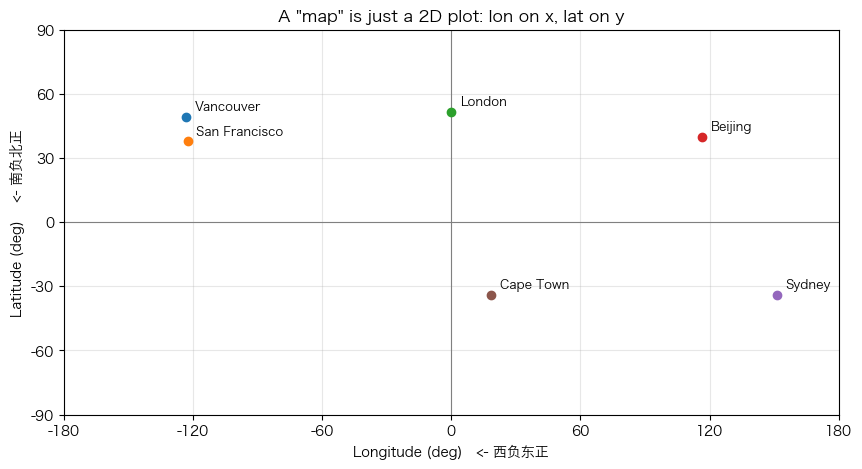

In [27]:
# 🧪 一张「地图」的最朴素形态：经度当 x，纬度当 y
cities = {
    'Vancouver':     (-123.12,  49.28),
    'San Francisco': (-122.42,  37.77),
    'London':        (  -0.13,  51.51),
    'Beijing':       ( 116.40,  39.90),
    'Sydney':        ( 151.21, -33.87),
    'Cape Town':     (  18.42, -33.92),
}

plt.figure(figsize=(10, 5))
plt.axhline(0, color='gray', lw=0.8)          # 赤道（纬度 0）
plt.axvline(0, color='gray', lw=0.8)          # 本初子午线（经度 0）

for name, (lon, lat) in cities.items():
    plt.plot(lon, lat, 'o', markersize=6)
    plt.text(lon + 4, lat + 3, name, fontsize=9)

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.xticks(range(-180, 181, 60))
plt.yticks(range(-90, 91, 30))
plt.grid(alpha=0.3)
plt.xlabel('Longitude (deg)   <- 西负东正')
plt.ylabel('Latitude (deg)    <- 南负北正')
plt.title('A "map" is just a 2D plot: lon on x, lat on y')
plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-8 | `cities = {...}` | 用字典存「城市名 → (经度, 纬度)」。⚠️ 注意 **经度在前、纬度在后** —— 这是地理界的通用顺序，和数学里的 (x, y) 一致 |
| 10 | `plt.axhline(0, ...)` | 画一条**水平参考线**（`axhline` = axes horizontal line）。这里代表赤道 |
| 11 | `plt.axvline(0, ...)` | 画一条**竖直参考线**，代表本初子午线（穿过伦敦格林尼治） |
| 13-15 | `for name, (lon, lat) in cities.items():` | 遍历字典。`.items()` 一次给出键和值，元组 `(lon, lat)` 直接被拆开 |
| 14 | `plt.plot(lon, lat, 'o', ...)` | 一个点就是一次 `plot` 调用 |
| 15 | `plt.text(lon + 4, lat + 3, name, ...)` | 在点的**右上方一点点**写名字。`+4` 和 `+3` 是手工偏移量，不加的话字会压在点上 |
| 17-18 | `plt.xlim(-180, 180)` / `plt.ylim(-90, 90)` | **把范围锁死成全地球**。不锁的话 matplotlib 只会显示数据所在的那一小块 |
| 19-20 | `plt.xticks(...)` | 手工指定刻度位置，让网格线整齐 |

**看图说话**：San Francisco 和 Vancouver 离得很近（都在北美西海岸），北京在右边偏上，悉尼和开普敦在南半球。**这些相对位置关系和真实世界是一致的** —— 说明「地图 = 2D 图」这句话没骗人。

> 💡 **为什么这张图看着有点「扁」？** 因为在真实地球上，赤道附近 1 度经度 ≈ 111 公里，而 60°N 处 1 度经度只有 ≈ 55 公里。但在这张图上，1 度经度**永远是同样宽**。这就是投影带来的变形 —— §5.2 专门讲它。
>
> ⚠️ **新手最容易搞反的**：经度是**东西**方向（-180 ~ 180），纬度是**南北**方向（-90 ~ 90）。记法：**「纬度」对应「横」的横线**（latitude 画成水平线），横线量的是南北位置。

## §5.2 🧪 什么是「投影」？用两个公式看明白

Cartopy 的文档里有一堆投影名字（PlateCarree、Mercator、Robinson、LambertConformal…），看着吓人。其实**所谓投影，就是一个把 (经度, 纬度) 换成 (x, y) 的函数**。

我们手写两个最常见的，对比一下变形。

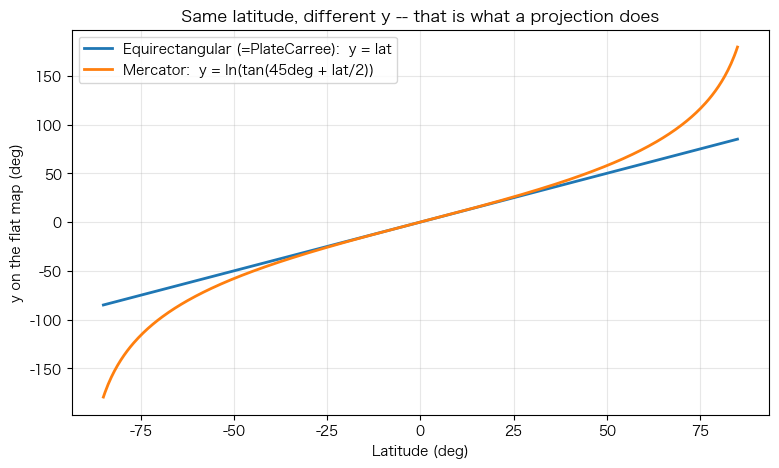

同样的纬度差，在两种投影下换来的图上高度：

  纬度     等距圆柱 y     墨卡托 y     墨卡托/等距圆柱
    0          0.00         -0.00           nan 倍
   30         30.00         31.47          1.05 倍
   45         45.00         50.50          1.12 倍
   60         60.00         75.46          1.26 倍
   75         75.00        116.17          1.55 倍
   85         85.00        179.41          2.11 倍

结论：等距圆柱「一格一格均匀」，墨卡托「越靠近两极拉得越狠」。
      这就是为什么墨卡托世界地图上格陵兰看着比非洲还大（实际非洲面积是它的 14 倍）。


In [28]:
# 🧪 投影 = 一个换算公式。手写两种，看差别
lat = np.linspace(-85, 85, 400)

y_equirect = lat                                                     # 等距圆柱：纬度直接用
y_mercator = np.degrees(np.log(np.tan(np.pi/4 + np.radians(lat)/2))) # 墨卡托

plt.figure(figsize=(9, 5))
plt.plot(lat, y_equirect, lw=2, label='Equirectangular (=PlateCarree):  y = lat')
plt.plot(lat, y_mercator, lw=2, label='Mercator:  y = ln(tan(45deg + lat/2))')
plt.xlabel('Latitude (deg)')
plt.ylabel('y on the flat map (deg)')
plt.title('Same latitude, different y -- that is what a projection does')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('同样的纬度差，在两种投影下换来的图上高度：')
print()
print('  纬度     等距圆柱 y     墨卡托 y     墨卡托/等距圆柱')
for la in [0, 30, 45, 60, 75, 85]:
    ye = la
    ym = float(np.degrees(np.log(np.tan(np.pi/4 + np.radians(la)/2))))
    print('  %3d      %8.2f      %8.2f        %6.2f 倍' % (la, ye, ym, ym/la if la else float('nan')))
print()
print('结论：等距圆柱「一格一格均匀」，墨卡托「越靠近两极拉得越狠」。')
print('      这就是为什么墨卡托世界地图上格陵兰看着比非洲还大（实际非洲面积是它的 14 倍）。')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `lat = np.linspace(-85, 85, 400)` | 纬度从 -85 到 85 取 400 个点。⚠️ **没取到 ±90** —— 因为墨卡托在极点处是**无穷大**（`tan(90°)` 不存在） |
| 4 | `y_equirect = lat` | 等距圆柱投影：**图上高度 = 纬度本身**。简单到不像个公式 |
| 5 | `y_mercator = ...` | 墨卡托投影：`ln(tan(45° + lat/2))`。`np.radians` 把角度转弧度（三角函数的输入必须是弧度），算完再用 `np.degrees` 转回角度 |
| 8-13 | 画两条曲线 | 横轴是纬度，纵轴是「投影到图上的 y」。**两条线分开 = 两种投影变形不同** |
| 21-24 | `for la in [0, 30, ...]:` | 把几个关键纬度上的数值列出来，并算出**放大倍数** |
| 25 | `ym/la if la else float('nan')` | ⚠️ 纬度为 0 时除法会炸，所以用条件表达式避开（`float('nan')` = 不是一个数） |

**输出的这张表就是「投影」的全部含义**：

| 纬度 | 等距圆柱 y | 墨卡托 y | 放大倍数 |
|---|---|---|---|
| 0° | 0 | 0 | — |
| 30° | 30 | 31.5 | 1.05 |
| 60° | 60 | 75.5 | 1.26 |
| 85° | 85 | 179.4 | 2.11 |

墨卡托把高纬度地区**拉伸**了 —— 所以那张经典的「墙上海报地图」里，格陵兰大得离谱。

> 💡 **`PlateCarree` 就是「等距圆柱」**：Cartopy 里 `ccrs.PlateCarree()` 对应的就是 `y = lat` 这个最简单的公式。课件说它是 "a common choice"，原因就是**够简单、够直观** —— 代价是两极附近变形严重（不过做课件、画数据点完全够用）。
>
> ⚠️ **名字里的坑**：Cartopy 的类名是 `PlateCarree`（**没有重音符号**），而课件正文写的是 "Plate Carrée"（**有重音**）。写代码时别把 é 敲进去，那会 `AttributeError`。
>
> 📌 **勘误 5（P5）**：课件说 Basemap "deprecated after 2016"。这个说法**方向对、但不够准确**：Basemap 是在 2016 年从 matplotlib 里**移出**、变成独立包 `basemap`；它后来还继续维护了几年（甚至支持到 Python 3.10+），只是官方明确推荐新项目改用 Cartopy。所以「deprecated after 2016」应理解为「**2016 年之后不再随 matplotlib 发布，官方建议改用 Cartopy**」。

## §5.3 三个库到底怎么选

| | Basemap | Cartopy | Folium |
|---|---|---|---|
| **底层** | matplotlib | matplotlib | Leaflet.js（网页） |
| **输出** | 静态图 | 静态图 | **交互式 HTML** |
| **在本 notebook 里能显示吗** | 能（PNG） | 能（PNG） | 能（HTML 嵌在输出里） |
| **能存成 PDF/论文插图吗** | 能 | ✅ 能 | ❌ 不能（是网页） |
| **投影系统** | 老式 | ✅ 基于 PROJ，专业 | 只支持网页地图那几种 |
| **要不要联网** | 要（下边界数据） | 要（首次下载 Natural Earth 数据，之后缓存） | 要（每次都要加载在线瓦片） |

> 💡 **一句话选型**：
> - 要**论文/报告插图** → Cartopy
> - 要**网页上让人缩放点选** → Folium
> - 只会在**老学长的代码**里见到 Basemap

> ⚠️ **`cartopy` 有个「第一次会很慢」的特点**：`ax.coastlines()` 首次运行时会去 Natural Earth 服务器下载海岸线数据（几十 MB），存在本地缓存目录里，之后就不再下载了。
>
> 所以**上课现场演示前，一定先跑一遍把数据下下来**，否则会对着空白的图等半天。§6 会告诉你数据存到哪去了。

---
# §6 · 用 Cartopy 画世界地图（Plotting Maps with Cartopy）

## 课件原文（P6）

- **Map Projections**: Cartopy supports various projections, with **Plate Carrée** being a common choice.
- **Steps to Plot a Map**:
  - Use **Matplotlib** for creating plots.
  - Set map projection: `ax = plt.axes(projection=ccrs.PlateCarree())`
  - Add features like coastlines and gridlines.

```python
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines(draw_labels=True)
plt.show()
```

- **Enhancements**: Background maps can be improved using downsampled Natural Earth images.

## 人话版

- **`ccrs` 是什么**：`cartopy.crs` 的常规缩写，`crs` = **C**oordinate **R**eference **S**ystem（坐标参考系）。所有投影类都住在这个模块里
- **画地图三步**：
  1. 用 matplotlib 开画布（和普通 2D 图完全一样）
  2. 建坐标区时把 `projection=` 设成某个**投影对象** —— 这一步就是「地图」和「普通 2D 图」的唯一区别
  3. 往上加要素：`coastlines()`（海岸线）、`gridlines()`（经纬网格）
- **`draw_labels=True`**：让经纬度数值标在图的边框上（不加就只有网格线、没有数字）
- **Natural Earth**：一个免费的地理数据集，Cartopy 的海岸线/国界/湖泊全都来自它，按分辨率分 110m / 50m / 10m 三档

## §6.1 先探测 `cartopy` 在不在

`cartopy` 不是 matplotlib 的标配，**要单独装**，而且它依赖一堆地理库（pyproj / shapely / pyshp）。所以这一节开始，先做个探测，装了就画、没装就跳过 —— 保证整份 notebook 无论如何都能从头跑到尾。

In [29]:
# 探测 cartopy
try:
    import cartopy
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
    print('✅ cartopy 已安装，版本', cartopy.__version__)
    print('   Natural Earth 数据缓存目录：', cartopy.config['data_dir'])
except ImportError:
    HAS_CARTOPY = False
    ccrs = None
    cfeature = None
    print('❌ 没有安装 cartopy —— §6、§7 的图会自动跳过（不会报错）')
    print()
    print('   安装方法：')
    print('       pip install cartopy')
    print('   或者（conda 环境更省事，不用自己编依赖）：')
    print('       conda install -c conda-forge cartopy')

❌ 没有安装 cartopy —— §6、§7 的图会自动跳过（不会报错）

   安装方法：
       pip install cartopy
   或者（conda 环境更省事，不用自己编依赖）：
       conda install -c conda-forge cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-4 | `import cartopy` / `... .crs` / `... .feature` | `cartopy` 是主包（拿版本号用）；`crs` 装着所有投影；`feature` 装着陆地/海洋/国界这些现成要素 |
| 5 | `HAS_CARTOPY = True` | **立一个旗子**。后面的格子都靠这个变量决定「画图」还是「打印一句跳过」 |
| 6 | `cartopy.config['data_dir']` | 打印缓存目录，见下面的 ⚠️ |
| 7-8 | `except ImportError:` | 只捕获「没装」这一种情况。⚠️ 如果 cartopy 装了但依赖坏了（比如 shapely 版本不对），会抛别的异常，**照样会崩** —— 那属于真问题，不该被吞掉 |
| 9-10 | `ccrs = None` / `cfeature = None` | 把名字定义成 `None`，这样后面即使不小心引用到也不会 `NameError`，而是更明确的 `AttributeError` |

> ⚠️ **`cartopy.config['data_dir']` 这个目录值得记一下**。第一次调用 `ax.coastlines()` 时，cartopy 会去 Natural Earth 的服务器下载一个几十 MB 的 zip，解压后放在这里。**之后就不再下载了**。
>
> 所以会出现这种迷惑现象：**同一个 notebook，第一次跑很慢、之后很快**。不是你的代码变快了，是数据被缓存了。
>
> 💡 如果磁盘紧张，可以事后手动删掉这个目录 —— 代价是下次再下载一遍。**上课演示前务必先跑一遍预热。**

## §6.2 课件原码跑一遍

下面是课件的 6 行代码，**一字未改**（除了外面套了一层「有没有 cartopy」的判断）。

In [30]:
if HAS_CARTOPY:
    plt.figure(figsize=(12, 8))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.coastlines()
    ax.gridlines(draw_labels=True)
    plt.show()
else:
    print('（跳过）这一格需要 cartopy：pip install cartopy')

（跳过）这一格需要 cartopy：pip install cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `plt.figure(figsize=(12, 8))` | 开画布，12x8 英寸。世界地图是宽扁的，所以用横向尺寸 |
| 3 | `ax = plt.axes(projection=ccrs.PlateCarree())` | **整个地图的灵魂就这一行**：`projection=` 接一个**投影对象**。`ccrs.PlateCarree()` 就是 §5.2 那个「等距圆柱」 |
| 4 | `ax.coastlines()` | 画海岸线。⚠️ 它的默认参数是 `resolution='auto'` —— **按视野自动挑分辨率**，不是固定 110m。世界地图上它会挑 110m，但一放大就换档。这个「自动」在 §7.2 会变成一个坑 |
| 5 | `ax.gridlines(draw_labels=True)` | 画经纬网格，并把经纬度数字标在**图的四条边上** |
| 6 | `plt.show()` | 渲染 |
| 7-8 | `else: print(...)` | 没装 cartopy 时的出口。**不画图，也不报错** |

**和普通 2D 图比，只差第 3 行**。除此之外 `figsize`、`show()` 全都一模一样 —— 这正好印证了课件那句「a map is a 2D plot」。

> ⚠️ **`plt.axes()` 的老毛病**（课件 P3、P6 都用了它）：`plt.axes()` 是在**当前画布上再铺一层坐标区**。如果这一格你重复运行两次，就会叠出两层地图 —— 看起来只是「颜色变深了」，其实是两张图摞在一起。
>
> **更稳的写法**是 `plt.subplots()`：
> ```python
> fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
> ```
> 它**每次都是全新的一块画布**，重复运行也不会叠。§7 我就用这个写法。
>
> 💡 顺带一提：`gridlines(draw_labels=True)` 是 Cartopy 0.18 之后才有的写法。更老的代码里会看到 `gl = ax.gridlines(); gl.xlabels_top = False` 这种手动关标签的写法 —— **那是老版本的 API，现在已经删了**，抄了会报 `AttributeError`。

## §6.3 🧪 同一个地球，四种投影

课件说 Plate Carrée 是 "a common choice"，但没说为什么还需要别的。最快的理解方式：**把同一个地球用不同投影画出来**。

In [31]:
if HAS_CARTOPY:
    projs = [
        ('PlateCarree  (等距圆柱)', ccrs.PlateCarree()),
        ('Mercator  (墨卡托)', ccrs.Mercator()),
        ('Robinson  (罗宾逊)', ccrs.Robinson()),
        ('Orthographic  (正射，像从太空看)', ccrs.Orthographic(-30, 40)),
    ]

    fig = plt.figure(figsize=(15, 8))
    for k, (name, proj) in enumerate(projs, start=1):
        ax = fig.add_subplot(2, 2, k, projection=proj)
        ax.coastlines('110m')
        ax.set_title(name, fontsize=11)
        # 正射投影自带一个圆边界，加个外框更好看
        try:
            ax.set_global()
        except Exception:
            pass

    plt.tight_layout()
    plt.show()
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-7 | `projs = [(名字, 投影对象), ...]` | 把四组「名字 + 投影」配好。**投影对象是从 `ccrs` 里造出来的**，`()` 不能省 |
| 4 | `ccrs.Orthographic(-30, 40)` | 正射投影要两个参数：**中心经度 -30、中心纬度 40** —— 决定「从太空的哪个位置看地球」 |
| 10 | `fig.add_subplot(2, 2, k, projection=proj)` | 2x2 布局里放第 k 个。`projection=` 每个子图可以不一样 |
| 11 | `ax.coastlines('110m')` | 这里显式给了 `'110m'`。**参数就是分辨率档位**：`'110m'` / `'50m'` / `'10m'`，数字越小越精细 |
| 13-16 | `try: ax.set_global() except: pass` | `set_global()` 让地图铺满整个投影范围。⚠️ 对某些投影（比如正射）它会抛异常，所以套了 `try` |

**四张图在讲什么**：

| 投影 | 形状 | 特点 | 典型用途 |
|---|---|---|---|
| **PlateCarree** | 矩形 | 经纬度直接当 x/y，**最简单** | 数据可视化、快速出图（课件的选择） |
| **Mercator** | 矩形（被纵向拉长） | 高纬度被放大，**但「等角」** —— 局部形状不变形 | 航海图、Google Maps 的底层瓦片 |
| **Robinson** | 椭圆 | 折中方案，**整体观感最接近真实** | 教科书里的世界地图、海报 |
| **Orthographic** | 圆 | 像从太空拍的照片 | 展示某个半球、卫星视角 |

> 💡 **投影没有「对错」，只有「合不合适」**：Mercator 会把格陵兰画得巨大（§5.2 算过），但航海时它是对的 —— 因为「等角」意味着你在图上画的直线就是恒定罗盘方位。**选投影前先想清楚你要表达什么。**

> ⚠️ **`ax.coastlines()` 的分辨率建议显式给**。它默认是 `resolution='auto'`（自适应），你不写它也「能看」—— 但那就意味着**图的精度由缩放范围决定，而不是由你的代码决定**。这正是 §7.2 的主题。

---
# §7 · 进阶地图：缩放与地理要素（Advanced Map Features in Cartopy）

## 课件原文（P7）

**Advanced Map Features in Cartopy**

- **Adding Features**:
  - `ax.set_extent()`: Zoom into specific regions by specifying longitude and latitude limits.
  - Add **land, ocean, borders, lakes, rivers** using Cartopy's built-in features.

```python
import cartopy.feature as cfeature

ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.LAKES, alpha=0.5)
```

- **Example**: Plotting high-resolution San Francisco Bay area with **10m resolution coastlines** and adding geographical features.

```python
ax.set_extent([-122.8, -122, 37.3, 38.3])
```

## 人话版

- **`ax.set_extent([...])`**：把镜头拉近到指定区域。参数是 `[西经, 东经, 南纬, 北纬]` —— **先经度后纬度**
- **`ax.add_feature(...)`**：往地图上贴现成的地理图层。课件用了四个：
  - `cfeature.LAND` 陆地（米色块）
  - `cfeature.OCEAN` 海洋（蓝色块）
  - `cfeature.BORDERS` 国界（线）
  - `cfeature.LAKES` 湖泊（`alpha=0.5` 半透明，能看到底下叠着的东西）
- **这个坐标** `[-122.8, -122, 37.3, 38.3]` 就是**美国加州旧金山湾区** —— 西边 -122.8°、东边 -122.0°，南北 37.3°N 到 38.3°N

> 📌 这一节藏着本章**最值得讲的一个机制**：课件正文说「10m resolution」，但代码里**一个 10m 都没写** —— 图却真的是 10m 的。为什么？见 §7.2。

## §7.1 课件原码跑一遍：旧金山湾

课件给的是两段片段（第一段加要素、第二段定范围），我把它拼成一个完整可跑的格子。

In [32]:
if HAS_CARTOPY:
    import cartopy.feature as cfeature

    print('画图之前：cfeature.LAND.scale =', cfeature.LAND.scale)

    fig, ax = plt.subplots(figsize=(8, 8),
                           subplot_kw={'projection': ccrs.PlateCarree()})

    ax.set_extent([-122.8, -122, 37.3, 38.3])        # 旧金山湾区

    ax.add_feature(cfeature.LAND)
    ax.add_feature(cfeature.OCEAN)
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAKES, alpha=0.5)

    ax.set_title('San Francisco Bay', fontsize=12)
    plt.show()

    print('画图之后：cfeature.LAND.scale =', cfeature.LAND.scale)
    print()
    print('⚠️ 这个属性变了！它读的不是「LAND 固定用哪一档」，')
    print('   而是「上一次画图时用过哪一档」—— 原因见 §7.2。')
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4 | `print('画图之前：...', cfeature.LAND.scale)` | 记下画图前的值。**这一行是为了和结尾对比** |
| 7-8 | `plt.subplots(figsize=(8,8), subplot_kw={'projection': ccrs.PlateCarree()})` | 比 `plt.axes()` 更稳的写法。⚠️ 投影要通过 `subplot_kw=` 传，因为 `subplots` 不接受直接的 `projection=` |
| 10 | `ax.set_extent([-122.8, -122, 37.3, 38.3])` | 定镜头范围。顺序是 `[经度最小, 经度最大, 纬度最小, 纬度最大]`，**不是** `[xmin, ymin, xmax, ymax]` |
| 12-15 | `ax.add_feature(...)` | 逐个贴图层。**顺序有讲究**：`LAND` 在前（铺底），`OCEAN` 在后（盖住海域），反了陆地会被海盖住 |
| 15 | `cfeature.LAKES, alpha=0.5` | 半透明，湖下面的陆地还能透出来 |
| 19 | `print('画图之后：...')` | ⚠️ **值变了** —— 从 `110m` 变成了 `10m`。这一格的重点就在这个反差上 |

**看图说话**：这张图的海湾轮廓很精细，金门海峡、湾内小岛都看得见。**但代码里没有任何地方写过「10m」。**

## §7.2 为什么课件没写「10m」，图却是 10m 的？

上一格的输出给出了线索：`cfeature.LAND.scale` 在画图**之前**是 `110m`，画完之后变成了 `10m`。

这不是 bug，是 cartopy 的一个**隐藏机制**。看源码里定义这些要素的那几行：

```python
auto_scaler = AdaptiveScaler('110m', (('50m', 50), ('10m', 15)))

LAND     = NaturalEarthFeature('physical', 'land',     auto_scaler, ...)
OCEAN    = NaturalEarthFeature('physical', 'ocean',    auto_scaler, ...)
COASTLINE= NaturalEarthFeature('physical', 'coastline',auto_scaler, ...)
BORDERS  = NaturalEarthFeature('cultural', 'admin_0_boundary_lines_land', auto_scaler, ...)
LAKES    = NaturalEarthFeature('physical', 'lakes',    auto_scaler, ...)
RIVERS   = NaturalEarthFeature('physical', 'rivers_lake_centerlines', auto_scaler, ...)
```

关键在那个 `auto_scaler`：**这些内置要素全都默认「按视野自动挑分辨率」**，规则是看**视野的短边**有多少度：

| 视野短边 | 自动选用的分辨率 | 典型场景 |
|---|---|---|
| > 50° | `110m` | 整个世界 |
| 15° ~ 50° | `50m` | 一个大洲 / 中国全境 |
| < 15° | `10m` | 一个省 / 一座城市 |

旧金山湾的视野是 0.8° x 1.0°，短边 0.8° 远小于 15° → **cartopy 悄悄换成了 10m**。

**所以课件那张图确实是 10m 的**，只是这个 10m 是「白捡的」，代码里完全看不出来。下面把这件事实测一遍。

In [33]:
if HAS_CARTOPY:
    sc = cfeature.LAND.scaler          # 所有内置要素共享的那个自适应选择器
    print('此刻 sc.scale =', sc.scale, '  <- 注意：这是「上一次用过的值」，不是固定的默认值')
    print('分档表     =', sc._limits, '   （外层的 110m 是"都不满足时的兜底"）')
    print()
    print('  %-12s %-10s %s' % ('场景', '视野短边', 'cartopy 自动选用的分辨率'))
    for name, ext in [('整个世界',   [-180, 180, -90, 90]),
                      ('北美大陆',   [-170, -50, 10, 75]),
                      ('中国全境',   [73, 136, 18, 54]),
                      ('珠三角',     [112.5, 114.5, 21.8, 23.5]),
                      ('旧金山湾',   [-122.8, -122, 37.3, 38.3])]:
        short = min(abs(ext[1] - ext[0]), abs(ext[3] - ext[2]))
        print('  %-12s %7.1f 度   %s' % (name, short, sc.scale_from_extent(ext)))
    print()
    print('⚠️ 注意最后一行：scale_from_extent() 会顺手把结果写回自己身上，')
    print('   所以 sc.scale 现在是', sc.scale, ' —— 这个全局状态被刚才那次调用改掉了。')
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `sc = cfeature.LAND.scaler` | 拿出那个自适应选择器对象。⚠️ **所有内置要素共用同一个它**（源码里是同一个 `auto_scaler` 变量） |
| 3-4 | `sc.scale` / `sc._limits` | `scale` 是「上次用过的值」，`_limits` 是分档表。`_limits` 带下划线说明是**内部属性**，这里为了讲原理才直接读它 |
| 9-10 | `for name, ext in [...]` | 拿五个不同大小的视野问它「你会选哪一档」 |
| 11 | `short = min(abs(...), abs(...))` | ⚠️ 是**短边**（`min`），不是长边、也不是面积。所以一个「很长但很窄」的视野也会被判成高分辨率 |
| 12 | `sc.scale_from_extent(ext)` | 真正做判断的函数，返回值就是它挑的分辨率 |
| 15-16 | `print(... sc.scale ...)` | 揭穿最后一件事：这个函数**有副作用**，会把结果写回 `sc._scale` |

> ⚠️ **这个机制有两个坑，都很实际**：
>
> **坑 1：你控制不了它。** 同一份代码，只改 `set_extent` 的范围，分辨率就跟着变。你调了半天样式，可能只是「视野变了导致数据源换了」。
>
> **坑 2：它是有状态的全局对象。** `cfeature.LAND.scale` 读到的是**上一次调用留下的值**，不是「LAND 固定用哪一档」。所以它会随着你画图的顺序变来变去 —— 调试时看到它「自己变了」，别慌，那是正常的。
>
> 💡 **结论：想要确定的输出，就永远显式写分辨率。** 自适应适合「快速看一眼」，不适合「要交的报告」。下一格演示怎么钉死它。

## §7.3 🧪 把分辨率钉死：110m / 50m / 10m 并排对比

想**锁定**某一档，必须显式写出来：

| 对象 | 写法 |
|---|---|
| `cfeature.LAND` / `OCEAN` / `LAKES` / `RIVERS` 等**要素** | `cfeature.LAND.with_scale('10m')` |
| `ax.coastlines()` **海岸线** | `ax.coastlines('10m')` |

⚠️ 两套 API 长得不一样：要素用 `.with_scale()`，海岸线用**位置参数**。混了就写不对。

下面把三档固定下来并排画 —— 你会看到金门海峡「从无到有」的全过程。

In [34]:
if HAS_CARTOPY:
    from shapely.geometry import box
    bbox = box(-122.8, 37.3, -122.0, 38.3)

    def n_vertices(scale):
        """数一数这一档的陆地数据，在旧金山湾这个框里还剩几个顶点"""
        n = 0
        for g in cfeature.LAND.with_scale(scale).geometries():
            x = g.intersection(bbox)
            if x.is_empty:
                continue
            if x.geom_type == 'Polygon':
                n += len(x.exterior.coords)
            else:
                n += sum(len(p.exterior.coords) for p in x.geoms)
        return n

    fig = plt.figure(figsize=(15, 6))
    for k, scale in enumerate(['110m', '50m', '10m'], start=1):
        ax = fig.add_subplot(1, 3, k, projection=ccrs.PlateCarree())
        ax.set_extent([-122.8, -122, 37.3, 38.3])

        # ⚠️ 必须用 .with_scale() 造一个「固定分辨率」的新对象；
        #    直接写 cfeature.LAND 会走自适应，三张图会一模一样
        ax.add_feature(cfeature.LAND.with_scale(scale))
        ax.add_feature(cfeature.OCEAN.with_scale(scale))
        ax.coastlines(scale, linewidth=0.6)
        ax.set_title('LAND %s   (%d 个顶点)' % (scale, n_vertices(scale)), fontsize=11)

    fig.suptitle('同一块地方，三档分辨率：金门海峡从「不存在」到「看得清」', fontsize=13)
    plt.tight_layout()
    plt.show()

    print('实测：旧金山湾这个框里，陆地多边形的顶点数')
    for s in ['110m', '50m', '10m']:
        print('   %-5s -> %3d 个' % (s, n_vertices(s)))
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 5-16 | `def n_vertices(scale):` | 自定义的小工具：数一数某一档数据在旧金山湾框里还剩几个顶点。**「量化细节」比「看着差不多」靠谱得多** |
| 9 | `for g in cfeature.LAND.with_scale(scale).geometries():` | 遍历这一档的所有陆地多边形。⚠️ `with_scale()` **每次都造一个新对象**，所以要重复调用就重复造，别指望它有缓存 |
| 10 | `x = g.intersection(bbox)` | 把多边形裁到旧金山湾这个框里。`box(xmin, ymin, xmax, ymax)` —— **注意这个顺序和 `set_extent` 不一样** |
| 12-15 | `if x.geom_type == 'Polygon': ... else: ...` | 裁剪结果可能是单个多边形（`Polygon`），也可能是多个拼成的一组（`MultiPolygon`）。两种都要处理，否则会 `AttributeError` |
| 21-26 | 三块子图，都加 `.with_scale(scale)` | **这是这一格的关键**：不写 `with_scale`，三张图会走自适应、结果完全一样 |
| 27 | `ax.coastlines(scale, linewidth=0.6)` | 海岸线也要显式给分辨率。`linewidth=0.6` 调细，否则 10m 数据线太密会糊成一片黑 |

**三张图的差别**（输出里也会打印顶点数）：

| 分辨率 | 顶点数 | 看到什么 |
|---|---|---|
| `110m` | **8** | 一条**斜直线** —— 旧金山湾**完全不存在** |
| `50m` | **45** | 海湾的轮廓出来了，但是**块状**，湾里的岛全没有 |
| `10m` | **321** | 金门海峡清楚、湾内小岛可见、岸线有细节 |

> ⚠️ **这就是「默认值」最危险的地方**：`cfeature.LAND` 在**世界地图**上完全够用（谁也不会盯着格陵兰的细节看），但一放大到城市尺度，它要么自动换成 10m（自适应时）、要么就只剩 8 个顶点（被 `with_scale('110m')` 钉死时）。
>
> 💡 **实用选择顺序**：先想清楚**图的最终尺寸**。整个世界 → `110m`；一个国家 → `50m`；一个城市 → `10m`。**分辨率永远跟着「图上有多少像素」走**，盲目上 10m 只会更慢更乱。

## §7.4 📌 勘误 6：课件正文说的「rivers」，代码里没有

把课件 P7 的**文字**和**代码**摆在一起看：

| 课件文字说 | 课件代码里 |
|---|---|
| "Add land, ocean, borders, lakes, **rivers**" | 只有 `LAND` `OCEAN` `BORDERS` `LAKES` —— **没有 `RIVERS`** |
| "with **10m resolution** coastlines" | 没有写任何分辨率（靠 `auto_scaler` 自动变成 10m，见 §7.2） |

> 📌 **勘误 6（P7）**：课件的文字与代码不一致 ——
> 1. 正文提到 **rivers**，代码里没有 `cfeature.RIVERS`；
> 2. 正文强调 **10m resolution**，代码里**一个 10m 都没写**。图之所以是 10m，是因为 `cfeature.*` 默认走自适应分辨率，**不是课件显式指定的**。换句话说：**这段代码换个缩放范围，精度就悄悄变了，而代码本身看不出来。**
>
> **建议的写法**（该写的都写出来）：
> ```python
> ax.coastlines('10m')                                  # 海岸线：位置参数给 '10m'
> ax.add_feature(cfeature.LAND.with_scale('10m'))        # 要素：用 .with_scale('10m')
> ax.add_feature(cfeature.RIVERS.with_scale('10m'))      # 补上正文说的 rivers
> ```

下面把「课件代码」和「课件正文描述的效果」并排画出来。

In [35]:
if HAS_CARTOPY:
    fig = plt.figure(figsize=(14, 7))

    # 左：完全照抄课件代码（自适应分辨率 + 没有 rivers）
    ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
    ax1.set_extent([-122.8, -122, 37.3, 38.3])
    ax1.add_feature(cfeature.LAND)
    ax1.add_feature(cfeature.OCEAN)
    ax1.add_feature(cfeature.BORDERS)
    ax1.add_feature(cfeature.LAKES, alpha=0.5)
    ax1.set_title('课件代码：没有 rivers（分辨率自适应）', fontsize=11)

    # 右：补上正文提到的 rivers，并把分辨率钉死在 10m
    ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
    ax2.set_extent([-122.8, -122, 37.3, 38.3])
    ax2.add_feature(cfeature.LAND.with_scale('10m'))
    ax2.add_feature(cfeature.OCEAN.with_scale('10m'))
    ax2.add_feature(cfeature.LAKES.with_scale('10m'), alpha=0.5)
    ax2.add_feature(cfeature.RIVERS.with_scale('10m'),
                    edgecolor='steelblue', linewidth=0.6)
    ax2.set_title('课件正文：10m + rivers（显式指定）', fontsize=11)

    plt.tight_layout()
    plt.show()

    print('两张图的海陆轮廓几乎一样 —— 因为左边的自适应也选中了 10m。')
    print('差别在两点：')
    print('  1. 右边多了河流的细线（课件正文承诺的 rivers）')
    print('  2. 右边的 10m 是「写死的」，换个范围也不会变；左边的会随范围变')
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-11 | 左边：四个 `add_feature` 不带分辨率 | **逐字照抄课件**。它靠自适应拿到 10m，所以看起来也不差 |
| 14-20 | 右边：每个要素都 `.with_scale('10m')` | 把分辨率**写死**，并补上课件正文说的 rivers |
| 19-20 | `cfeature.RIVERS.with_scale('10m'), edgecolor='steelblue', linewidth=0.6` | 河流默认是黑色细线，在这张图上太扎眼，改成蓝色细线。⚠️ `linewidth` 一定要小，10m 的河流数据非常密 |
| 25-28 | `print(...)` | **把「为什么两张图看着差不多」解释清楚**，否则读者会以为右边白写了 |

> 💡 **这一格真正想传达的不是「课件错了」，而是「看不出差别」本身就是问题**：左边那张图的精度**不由代码决定，而由当时的缩放范围决定**。今天画出来是 10m，明天把范围改成整个加州，它就会悄悄变成 50m —— 而代码一个字都没改。
>
> **能写死的就写死。** 报告和论文尤其如此。

## §7.5 🧪 换成别的地方：改两个数字就行

`set_extent` 的四个数字就是「镜头」。换成自己关心的区域，其他一行都不用动。

⚠️ 注意这一格我**故意显式写 `with_scale('10m')`** —— 因为珠三角、长三角这种尺度（视野约 2°），自适应的短边是 2°，确实也会选 10m；但**夏威夷**那块视野是 6°，自适应只会给 50m。**写死就不会有这种意外。**

In [36]:
if HAS_CARTOPY:
    regions = [
        ('Pearl River Delta  珠三角', [112.5, 114.5, 21.8, 23.5]),
        ('Taiwan Strait  台湾海峡',    [119.0, 122.5, 22.0, 25.5]),
        ('Yangtze Delta  长三角',      [120.5, 122.5, 30.5, 32.5]),
        ('Hawaii  夏威夷',             [-160.5, -154.5, 18.5, 22.5]),
    ]

    fig = plt.figure(figsize=(14, 10))
    for k, (name, extent) in enumerate(regions, start=1):
        ax = fig.add_subplot(2, 2, k, projection=ccrs.PlateCarree())
        ax.set_extent(extent)
        ax.add_feature(cfeature.LAND.with_scale('10m'))
        ax.add_feature(cfeature.OCEAN.with_scale('10m'))
        ax.coastlines('10m', linewidth=0.6)
        ax.set_title(name, fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print('（跳过）这一格需要 cartopy')

（跳过）这一格需要 cartopy


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-7 | `regions = [(名字, [范围]), ...]` | 把四块区域的经纬度范围列成表。**这就是「地图配置」应有的样子：数据驱动** |
| 11 | `ax.set_extent(extent)` | `extent` 就是列表里的四个数，直接传进去 |
| 12-13 | `.with_scale('10m')` | 这四块都是「一个省 / 一个群岛」的尺度，10m 合适 |
| 14 | `ax.coastlines('10m', linewidth=0.6)` | 线再细一点 |

> 💡 **把范围写成列表、用循环画**，是画一组区域图的正确姿势。比手写四遍 `set_extent` 少了十几行重复代码，改一处范围也不用满地找。
>
> ⚠️ **范围顺序再强调一次**：`[西经, 东经, 南纬, 北纬]`。想画「东经 112.5 到 114.5」就写 `112.5, 114.5`（都是正数）；想画「西经 160.5 到 154.5」要写 `-160.5, -154.5`（**西经是负数，且小的在前**）。写反了图会跑到地球另一边去 —— 而且**不会报错**。

---
# §8 · 动画（Animations in Python）

## 课件原文（P8）

**Animations in Python**

- **Definition**:
  - An animation is a sequence of still frames displayed rapidly to create the illusion of motion.
  - Useful for better visual representation of dynamic systems compared to static plots.
- **Python Tools**:
  - The primary tool for creating animations in Python is the `matplotlib.animation.Animation` class.
  - This class offers a framework to build animation functionality.
- **Basic Steps for Creating an Animation**:
  1. **Define Metadata**: Define movie metadata such as title, artist, and comments using `manimation.writers['ffmpeg']`.
  2. **Initialize Background**: Set up static background elements like axis labels and curves.
  3. **Update Frames**: Inside a loop, update objects (like a moving point) for each frame.

**（课件右侧代码）**

```python
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Data generation
n = 1000
x = np.linspace(0, 6 * np.pi, n)
y = np.sin(x)

# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(0, 6 * np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('sin(x)')

# Plot the sine wave (background)
sine_line, = ax.plot(x, y, 'b')

# Create an empty red circle that will move
red_circle, = ax.plot([], [], 'ro', markersize=10)

# Initialize the animation
def init():
    red_circle.set_data([], [])
    return red_circle,

# Update function for animation
def update(frame):
    red_circle.set_data([x[frame]], [y[frame]])
    return red_circle,

# Create the animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=n,
    init_func=init,
    interval=15,
    blit=True
)

plt.show()
```

## 人话版

- **动画的本质**：**一堆静止的图片**，快速连续播放，眼睛就以为它在动。所以做动画 = 「写一个函数，告诉我第 k 帧长什么样」
- **关键抽象**：
  - **背景**：从头到尾不变的东西（正弦曲线、坐标轴标签），**只画一次**
  - **动的东西**：每帧只改它的数据（红圆圈的位置）
- **`FuncAnimation` 的三个零件**：
  1. `init_func`：第 0 帧之前调用一次，负责「清空画布」
  2. `update(frame)`：**核心**。参数 `frame` 是帧号（0, 1, 2, …），你要在这个函数里把「第 frame 帧」画出来
  3. `frames=n`：一共多少帧；`interval=15` 是帧间隔（毫秒）
- **`blit=True`**：只重画「变了的部分」，速度更快（但也更容易出 bug）

## §8.1 课件原码跑一遍

⚠️ 这一段课件代码**会覆盖前面用过的 `x` 和 `y`**（§2 里它们是 `[-5, 5]` 上的 100 个点）。在 notebook 里这是很典型的坑 —— 我把这件事在注释里标出来。

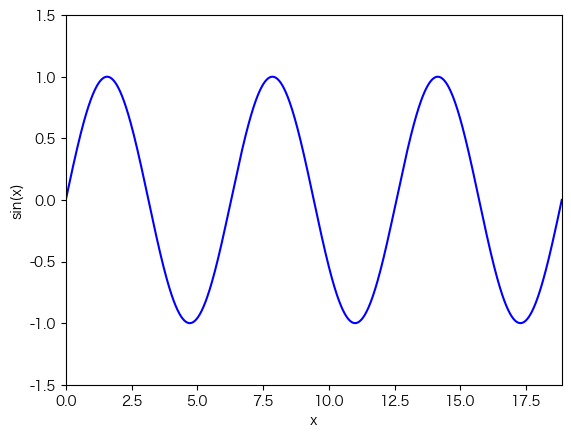

动画对象建好了： FuncAnimation
帧数 = 1000 ，间隔 = 15 ms，总时长约 15.0 秒


In [37]:
# 课件 P8：正弦波动画
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Data generation
n = 1000
x = np.linspace(0, 6 * np.pi, n)      # ⚠️ 这里的 x,y 覆盖了 §2 里同名的变量！
y = np.sin(x)

# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(0, 6 * np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('sin(x)')

# Plot the sine wave (background)
sine_line, = ax.plot(x, y, 'b')

# Create an empty red circle that will move
red_circle, = ax.plot([], [], 'ro', markersize=10)

# Initialize the animation
def init():
    red_circle.set_data([], [])
    return red_circle,

# Update function for animation
def update(frame):
    red_circle.set_data([x[frame]], [y[frame]])
    return red_circle,

# Create the animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=n,
    init_func=init,
    interval=15,
    blit=True
)

plt.show()

print('动画对象建好了：', type(ani).__name__)
print('帧数 =', n, '，间隔 = 15 ms，总时长约', round(n * 15 / 1000, 1), '秒')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 7-8 | `x = np.linspace(0, 6*np.pi, n)` / `y = np.sin(x)` | 造数据。⚠️ **这里重用了一直在用的名字 `x``y`** —— 后面如果再想用 §2 那组 `x`，就已经被换掉了。**在 notebook 里给变量起名要当心「隔了好几格还记得它是什么」** |
| 12-16 | `fig, ax` + `set_xlim` / `set_ylim` | 建画布并**锁死坐标范围**。⚠️ 动画里不锁范围，matplotlib 会每帧重新自动缩放，画面会抖 |
| 18 | `sine_line, = ax.plot(x, y, 'b')` | **背景**，画一次就够。⚠️ 等号后面的**逗号不能省** —— 见下面 ⚠️ |
| 21 | `red_circle, = ax.plot([], [], 'ro', markersize=10)` | **动的东西**。⚠️ 注意 `[]` 空列表 —— **初始状态一个点都不画**，等 `update` 来填 |
| 24-26 | `def init(): red_circle.set_data([], []); return red_circle,` | 清空函数。**返回的必须是「可迭代对象」**（所以结尾有个逗号） |
| 29-31 | `def update(frame): ...` | **核心**。`frame` 是帧号，`x[frame]``y[frame]` 取出第 frame 个点，用 `set_data` 挪动红圈 |
| 34-41 | `animation.FuncAnimation(...)` | 把零件组装成动画对象。⚠️ **一定要用变量接住**（这里是 `ani`）—— 不接住会被垃圾回收，动画直接消失 |
| 43 | `plt.show()` | **这里就是问题所在** —— 见 📌 勘误 7 |

> ⚠️ **`line, = ax.plot(...)` 里的逗号是干什么的？**
> `ax.plot()` 返回的是一个**列表**（哪怕只画了一条线，也是 `[Line2D]`）。加逗号是「解包」：`line, = [obj]` 把 `obj` 取出来。**不加逗号得到的是列表**，后面 `line.set_data()` 就会报 `AttributeError: 'list' object has no attribute 'set_data'`。
>
> 这是 matplotlib 动画代码里最常见的报错，**没有之一**。

### 📌 勘误 7（P8）：`plt.show()` 看不到动画

上面那一格跑完，你只会看到**一条蓝色正弦曲线**（红圈还没画上去，因为初始数据是空的）—— **它不会动**。

课件把 `plt.show()` 当作「播放动画」，这在**老的 GUI 窗口**（比如 `python script.py` 弹出的窗口）里确实成立，但在 **Jupyter 的 inline 后端**里不成立：inline 后端只会把当前画布**拍一张静态快照**交出去。

> 📌 **勘误 7（P8）**：课件用 `plt.show()` 结尾，在 Jupyter notebook 里**看不到动画**，只能看到一张静态的起始帧。
>
> **三种能看到动画的正确做法**：
>
> | 做法 | 代码 | 能在 notebook 里动？ | 能导出到 PDF？ |
> |---|---|---|---|
> | ① 存成 GIF/MP4 再显示 | `ani.save('a.gif', writer='pillow')` | ✅（GIF 会动） | 只显示第一帧 |
> | ② 内嵌 JS 播放器 | `HTML(ani.to_jshtml())` | ✅ | ❌（很重，见下） |
> | ③ 电影胶片图（静态多帧） | 画一排子图 | ❌（是静的） | ✅ |
>
> ⚠️ **关于 ② 的一个实测数据**：`to_jshtml()` 会把**每一帧都存成一张 PNG** 塞进 HTML 里。我实测 **60 帧 = 1.9 MB**；课件用的 `n=1000`，直接就是 **30 MB 上下**。
>
> 所以本 notebook **故意不跑 `to_jshtml()`** —— 那会把文件撑爆。做法 ① 和 ③ 才是能交付的。

下面两种做法都演示一遍。

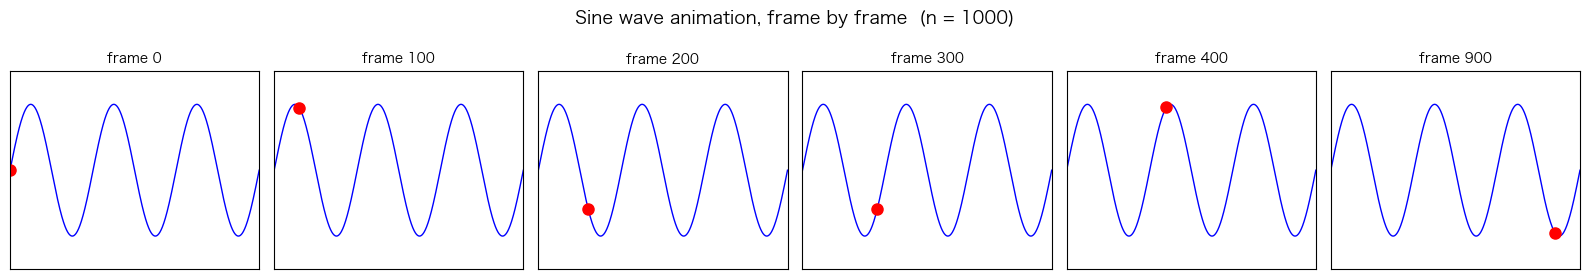

把 1000 帧里抽 6 帧摆出来，读者就能看懂「点是怎么走的」
这比一张静态图信息量大，又不像 GIF 那样依赖浏览器


In [38]:
# 🧪 做法 ③：电影胶片图（一排静态帧）—— 这是唯一能安全进 PDF 的做法
fig, axes = plt.subplots(1, 6, figsize=(16, 2.8))

offsets = [0, 100, 200, 300, 400, 900]        # 取 6 个有代表性的帧号
for k, (axk, idx) in enumerate(zip(axes, offsets)):
    axk.plot(x, y, 'b', linewidth=1)                       # 背景曲线
    axk.plot(x[idx], y[idx], 'ro', markersize=8)           # 该帧的红圈
    axk.set_xlim(0, 6 * np.pi)
    axk.set_ylim(-1.5, 1.5)
    axk.set_xticks([])
    axk.set_yticks([])
    axk.set_title('frame %d' % idx, fontsize=10)

fig.suptitle('Sine wave animation, frame by frame  (n = 1000)', fontsize=13)
plt.tight_layout()
plt.show()

print('把 1000 帧里抽 6 帧摆出来，读者就能看懂「点是怎么走的」')
print('这比一张静态图信息量大，又不像 GIF 那样依赖浏览器')

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `fig, axes = plt.subplots(1, 6, figsize=(16, 2.8))` | 一排 6 个子图。高度压到 2.8 英寸，做成「胶片」的细长比例 |
| 4 | `offsets = [0, 100, 200, 300, 400, 900]` | 手工挑 6 个帧号。**最后一个故意跳大一点**（900 而不是 500），让人看到「绕了好几圈」 |
| 6 | `for k, (axk, idx) in enumerate(zip(axes, offsets))` | 用 `enumerate` 只是为了拿到 `k`（其实这里用不到），`zip` 才是把子图和帧号配起来 |
| 7-8 | `axk.plot(x, y, 'b', ...)` / `axk.plot(x[idx], y[idx], 'ro', ...)` | **每帧都重画一遍背景**。在静态胶片图里这样做没问题（数据量小），但在真动画里就要靠 `blit` 来避免重画 |
| 10-11 | `axk.set_xticks([])` | 把刻度数字去掉 —— **6 张图各标一遍坐标轴会很乱**，只在整体上说清楚就够了 |

> 💡 **为什么 `x[idx]` 能直接用？** `y = np.sin(x)` 里 `x` 是**等距**的，所以「第 idx 个点」就是「曲线上的一个位置」。如果 `x` 不等距，就得改用 `np.interp` 之类的插值 —— 这是 3D 动画里常见的坑。

已保存 sine_wave_demo.gif   大小 = 32 KB



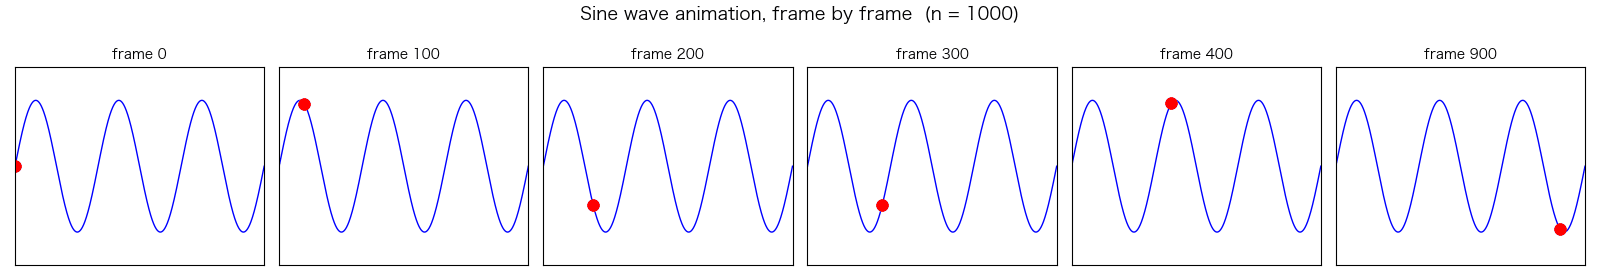

In [39]:
# 🧪 做法 ①：存成 GIF（PillowWriter 不需要任何外部程序）
from IPython.display import Image, display

ani_small = animation.FuncAnimation(
    fig, update,
    frames=60,                 # ⚠️ 演示只用 60 帧：1000 帧的 GIF 会有好几 MB
    init_func=init,
    interval=20,
    blit=True
)

ani_small.save('sine_wave_demo.gif', writer='pillow', fps=25)

import os
print('已保存 sine_wave_demo.gif   大小 = %.0f KB' % (os.path.getsize('sine_wave_demo.gif') / 1024))
print()
display(Image(filename='sine_wave_demo.gif'))

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-9 | `ani_small = animation.FuncAnimation(fig, update, frames=60, ...)` | 重新建一个**只有 60 帧**的动画。⚠️ 复用同一套 `fig` / `update` / `init` —— 数据全变了，只有「帧数」变小 |
| 11 | `ani_small.save('sine_wave_demo.gif', writer='pillow', fps=25)` | **存盘**。`writer='pillow'` 用的是 Pillow（PIL），**纯 Python 实现，不需要 ffmpeg** |
| 11 | `fps=25` | frames per second，每秒 25 帧。`60 帧 / 25 fps` ≈ 2.4 秒 |
| 17 | `display(Image(filename='sine_wave_demo.gif'))` | 把 GIF 显示出来。**在浏览器里它是会动的** |

**为什么 `frames=60` 而不是 1000？** 因为 GIF 是**逐帧无损**存的：本页这张 60 帧 ≈ 32 KB，而 §9.3 换个 8x3 英寸的画布存 240 帧就接近 700 KB。按这个比例，1000 帧轻松到几 MB —— 塞进 notebook 里纯属自找麻烦。

> 💡 **`pillow` 是无依赖的保底方案**：`matplotlib` 装好的时候 `Pillow` 一般也在了。`writers.list()` 里能看到 `'pillow'` 和 `'html'` 两个**永远可用**的 writer。
>
> ⚠️ **GIF 的两个先天不足**：① 最多 256 色，渐变会有色带；② 文件比 mp4 大得多。**要清晰、要小，还是得用 mp4（下一节）。**

## §8.2 `update` 函数：动画的真正核心

把课件那个 `update` 单拎出来看，它只做了一件事：

```python
def update(frame):
    red_circle.set_data([x[frame]], [y[frame]])
    return red_circle,
```

| 部分 | 含义 |
|---|---|
| `frame` | 帧号，`FuncAnimation` 会自动从 0 数到 `n-1` |
| `x[frame]``y[frame]` | 第 frame 帧时，红圈应该在的坐标 |
| `set_data([...], [...])` | **只改数据，不重建对象** —— 这是动画能跑得动的关键 |
| `return red_circle,` | `blit=True` 时，告诉 matplotlib「**这个对象变了，重画它**」 |

> ⚠️ **`set_data` 的参数必须是「序列」**：`set_data(x[frame], y[frame])` 会报错，要写成 `set_data([x[frame]], [y[frame]])`（各套一层列表）。**这是新手第二个最常踩的坑。**
>
> 💡 **理解了 `update`，你就能做任何动画**：把「第 frame 帧的点在哪」算出来就行。比如让红圈沿水平方向匀速走 `set_data([frame], [np.sin(frame)])`；或者画一个逐渐长出来的曲线 `sine_line.set_data(x[:frame], y[:frame])`。

---
# §9 · 把动画存成 mp4（Example: Sine Wave Animation）

## 课件原文（P9）

**Example: Sine Wave Animation**

- **Objective**: Animate a red circle moving along a blue sine wave.
- **Key Components of Code**:
  - Import required libraries: numpy, matplotlib.pyplot, and matplotlib.animation.
  - Set up metadata for the movie (e.g., frames per second: fps=15).
  - **Sine Wave Setup**: Use `np.linspace()` to generate 1000 data points for x, and `np.sin(x)` for the sine curve.
  - **Figure Initialization**: Plot the sine wave and an empty placeholder for the red circle.
  - **Frame Updates**: For each frame in a loop, update the position of the red circle along the sine wave.
  - **Saving the Animation**: Output the animation as an mp4 file with a resolution of 100 dpi using `writer.saving()`.

```python
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as manimation

# Data generation
n = 1000
x = np.linspace(0, 6*np.pi, n)
y = np.sin(x)

# Define movie metadata
FFMpegWriter = manimation.writers['ffmpeg']
metadata = dict(title='Sine Wave Animation', artist='Matplotlib', comment='A red circle moving along a sine wave')
writer = FFMpegWriter(fps=15, metadata=metadata)

# Initialize the movie
fig, ax = plt.subplots()
ax.set_xlim(0, 6*np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('sin(x)')

# Plot the sine wave
sine_line, = ax.plot(x, y, 'b')
red_circle, = ax.plot([], [], 'ro', markersize=10)

# Update the frames for the movie
with writer.saving(fig, "sine_wave_animation.mp4", 100):
    for i in range(n):
        red_circle.set_data([x[i]], [y[i]])  # Update the red circle's position
        writer.grab_frame()  # Capture the frame

print("Animation saved as sine_wave_animation.mp4")
```

## 人话版

- 和 §8 的动画**数据完全一样**，只是换了个「出口」：§8 是「在屏幕上播」，这一节是「写成文件」
- **`manimation.writers['ffmpeg']`**：从 matplotlib 的 writer 登记表里取出 ffmpeg 这个「录像机」
- **`metadata`**：写进 mp4 文件头的信息 —— 标题、作者、备注。用 `dict(...)` 一次性给出
- **`writer.saving(fig, 文件名, dpi)`**：一个**上下文管理器**，`with` 块内部每调用一次 `grab_frame()` 就抓一帧
- **`writer.grab_frame()`**：把**当前画布**拍下来写成视频的一帧。所以循环里的顺序是：先 `set_data` 挪动红圈，再 `grab_frame`

## §9.1 课件原码跑一遍 —— 大概率会失败

先说结论：**课件这段代码要求你的电脑上装了 `ffmpeg` 这个外部程序**。它不是一个 Python 包，`pip install` 装不到它。

所以我们用 `try/except` 把它包起来跑，看看会发生什么。

In [40]:
# 课件 P9：存成 mp4
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as manimation

# Data generation
n = 1000
x = np.linspace(0, 6*np.pi, n)
y = np.sin(x)

try:
    # Define movie metadata
    FFMpegWriter = manimation.writers['ffmpeg']      # <-- 课件这一行：没装 ffmpeg 就在这里炸
    metadata = dict(title='Sine Wave Animation', artist='Matplotlib', comment='A red circle moving along a sine wave')
    writer = FFMpegWriter(fps=15, metadata=metadata)
    print('✅ ffmpeg 可用，下面开始写 mp4（1000 帧，可能要跑一会儿）')
except RuntimeError as e:
    writer = None
    print("❌ 失败在这一行：  FFMpegWriter = manimation.writers['ffmpeg']")
    print('   抛出的异常：RuntimeError:', e)
    print()
    print('   注意错误类型：是 RuntimeError，不是 ImportError，也不是 FileNotFoundError。')
    print('   课件后面的 20 行代码，一行都跑不到 —— 这就是 📌 勘误 8。')
    print('   替代方案见 §9.3：把 ffmpeg 换成 pillow，其余一行都不用动。')

if writer is not None:
    # Initialize the movie
    fig, ax = plt.subplots()
    ax.set_xlim(0, 6*np.pi)
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel('x')
    ax.set_ylabel('sin(x)')

    # Plot the sine wave
    sine_line, = ax.plot(x, y, 'b')
    red_circle, = ax.plot([], [], 'ro', markersize=10)

    # Update the frames for the movie
    with writer.saving(fig, "sine_wave_animation.mp4", 100):
        for i in range(n):
            red_circle.set_data([x[i]], [y[i]])  # Update the red circle's position
            writer.grab_frame()  # Capture the frame

    plt.close(fig)
    print("Animation saved as sine_wave_animation.mp4")

❌ 失败在这一行：  FFMpegWriter = manimation.writers['ffmpeg']
   抛出的异常：RuntimeError: Requested MovieWriter (ffmpeg) not available

   注意错误类型：是 RuntimeError，不是 ImportError，也不是 FileNotFoundError。
   课件后面的 20 行代码，一行都跑不到 —— 这就是 📌 勘误 8。
   替代方案见 §9.3：把 ffmpeg 换成 pillow，其余一行都不用动。


上面这一格**故意用 `try/except` 包了一层** —— 否则整个 notebook 会在这里中断，后面的内容你全都看不到。它实际打印出来的是：

```
❌ 失败在这一行：  FFMpegWriter = manimation.writers['ffmpeg']
   抛出的异常：RuntimeError: Requested MovieWriter (ffmpeg) not available
```

三件事值得注意：

1. 失败发生在 `manimation.writers['ffmpeg']` 这一句 —— **还没开始画图就挂了**；
2. 异常类型是 `RuntimeError`，**不是** `ImportError`（ffmpeg 根本不是 Python 包），也**不是** `FileNotFoundError`；
3. 课件后面的 20 行代码，**一行都跑不到**。

> 📌 **勘误 8（P9）**：课件直接把 `manimation.writers['ffmpeg']` 当成一定能取到的东西。实际上
> **只要电脑上没装 ffmpeg，这一行立刻抛 `RuntimeError`**，后面 20 行代码一行都跑不到。
>
> 而且报错信息只说「ffmpeg 不可用」，**不会告诉你该怎么装**。
>
> **两种解法**：

**解法 A：装上 ffmpeg（想要 mp4 就必须这样做）**

```bash
# macOS
brew install ffmpeg

# Windows（用 conda 最省事）
conda install -c conda-forge ffmpeg

# Linux
sudo apt install ffmpeg
```

装完**必须重启 Jupyter 内核**（因为 matplotlib 是在 import 时探测 ffmpeg 的，不重启认不出来），然后 `manimation.writers.list()` 里才会出现 `'ffmpeg'`。

**解法 B：换一个 writer（不想装 ffmpeg 就走这条）**

```python
# PillowWriter 纯 Python，永远可用，输出 GIF
writer = manimation.writers['pillow'](fps=15, metadata=metadata)
```

两条路的具体代码在下面。

⚠️ 另外还有个小坑：课件的 `writer.saving(fig, "sine_wave_animation.mp4", 100)` 里那个 `100` 是 **dpi**（课件正文写对了："with a resolution of 100 dpi"）。**dpi 越高文件越大**，1000 帧的 mp4 在 100 dpi 下大概几十 MB。

## §9.2 🧪 解法 A：先检查 ffmpeg 在不在

在写动画代码之前，**先探测**，这样能给出人话提示，而不是让用户对着 `RuntimeError` 发呆。

In [41]:
# 🧪 先探测 ffmpeg，再决定用哪个 writer
import matplotlib.animation as manimation

print('matplotlib 认得的 writer：', manimation.writers.list())
print()

if 'ffmpeg' in manimation.writers.list():
    print('✅ ffmpeg 可用 -> 可以直接存 mp4')
else:
    print('❌ ffmpeg 不可用 -> 走 PillowWriter 存 GIF 的路线')
    print()
    print('   想存 mp4 的话，装一个 ffmpeg 然后重启内核：')
    print('       macOS  : brew install ffmpeg')
    print('       conda  : conda install -c conda-forge ffmpeg')
    print('       Ubuntu : sudo apt install ffmpeg')

print()
print('注意 "pillow" 和 "html" 这两个永远都在：')
print('  pillow -> 存 GIF（纯 Python，无需外部程序）')
print('  html   -> 存成一个网页播放器（ani.to_jshtml()）')

matplotlib 认得的 writer： ['pillow', 'html']

❌ ffmpeg 不可用 -> 走 PillowWriter 存 GIF 的路线

   想存 mp4 的话，装一个 ffmpeg 然后重启内核：
       macOS  : brew install ffmpeg
       conda  : conda install -c conda-forge ffmpeg
       Ubuntu : sudo apt install ffmpeg

注意 "pillow" 和 "html" 这两个永远都在：
  pillow -> 存 GIF（纯 Python，无需外部程序）
  html   -> 存成一个网页播放器（ani.to_jshtml()）


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4 | `manimation.writers.list()` | 返回 matplotlib **当前能用的所有 writer 名字**。这是个实时探测 —— 装完 ffmpeg 不重启内核，这里就不会变 |
| 7 | `if 'ffmpeg' in ...` | 用「在不在列表里」判断，**而不是 `try/except`** —— 更清晰，也不会有异常开销 |
| 13-16 | 打印安装命令 | **好代码应该告诉用户「怎么办」**，而不是只报「不行」 |

> 💡 **这个「先探测、再分支」的模式值得抄**：写给别人用的 notebook，凡是依赖外部程序/可选库的地方，都在最前面探测一次，把结果存成 `HAS_XXX` 变量。§6 的 `HAS_CARTOPY` 是同一个套路。

## §9.3 🧪 解法 B：用 PillowWriter 存 GIF（不装 ffmpeg 也能出片）

把课件的代码改两处：`ffmpeg` → `pillow`，文件名 `.mp4` → `.gif`。**其他一行都不用动。**

已保存 sine_wave_animation.gif   大小 = 699 KB
帧数 = 240，fps = 15 -> 时长约 16.0 秒


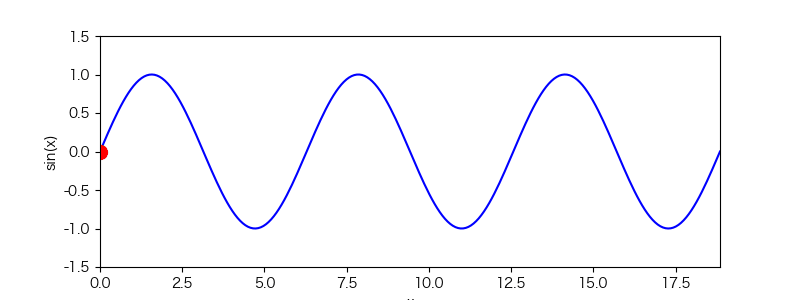

In [42]:
# 🧪 课件 P9 的等价实现：只把 writer 换掉
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as manimation
import os

n = 240                                  # 240 帧 @ 15fps = 16 秒，够看清了
x2 = np.linspace(0, 6*np.pi, n)
y2 = np.sin(x2)

# 只有这一行和课件不同：ffmpeg -> pillow
PillowWriter = manimation.writers['pillow']
metadata = dict(title='Sine Wave Animation', artist='Matplotlib',
                comment='A red circle moving along a sine wave')
writer = PillowWriter(fps=15, metadata=metadata)

fig2, ax2 = plt.subplots(figsize=(8, 3))
ax2.set_xlim(0, 6*np.pi)
ax2.set_ylim(-1.5, 1.5)
ax2.set_xlabel('x')
ax2.set_ylabel('sin(x)')

sine_line, = ax2.plot(x2, y2, 'b')
red_circle, = ax2.plot([], [], 'ro', markersize=10)

# 和课件完全一样的写法：with writer.saving(...) + 循环 grab_frame()
with writer.saving(fig2, 'sine_wave_animation.gif', 100):
    for i in range(n):
        red_circle.set_data([x2[i]], [y2[i]])   # 挪动红圈
        writer.grab_frame()                     # 抓一帧

plt.close(fig2)
print('已保存 sine_wave_animation.gif   大小 = %.0f KB' % (os.path.getsize('sine_wave_animation.gif') / 1024))
print('帧数 = %d，fps = 15 -> 时长约 %.1f 秒' % (n, n / 15))

from IPython.display import Image, display
display(Image(filename='sine_wave_animation.gif'))

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 6 | `n = 240` | 从 1000 降到 240。240 帧的 GIF 实测约 700 KB；1000 帧会到 3 MB 上下，所以这里砍到 240 —— 刚好够看清一轮往返 |
| 12 | `PillowWriter = manimation.writers['pillow']` | **唯一需要改的一行**。`'pillow'` 这个名字永远在 `writers.list()` 里 |
| 13-14 | `metadata = dict(...)` | 元数据。⚠️ GIF 格式**不支持** title/artist 这些字段，`PillowWriter` 会直接忽略它们 —— **写了不报错，但也没用**。留着是为了和课件对照 |
| 25-29 | `with writer.saving(fig2, 'sine_wave_animation.gif', 100):` | **和课件的写法逐字一致**（除了文件名）。这就是这个例子的价值：**证明「换 writer」是真的只改一行** |
| 27 | `red_circle.set_data([x2[i]], [y2[i]])` | 和课件一样：先挪红圈 |
| 28 | `writer.grab_frame()` | 再抓帧。**顺序绝不能反** —— 反了就永远是上一帧的画面 |
| 31 | `plt.close(fig2)` | 关掉画布。⚠️ 不关的话，`with` 块结束后这张图会作为**静态图**再显示一遍，等于白白多一张 |

> 💡 **`writer.saving(...)` 的第三个参数是 dpi**，和课件一致（100）。GIF 想小一点，把它降到 60~80 效果也够。
>
> ⚠️ **别在 `with` 块里调用 `plt.show()`**：会打乱 `grab_frame()` 的取景。抓帧期间就让画布安安静静地待在后台。

## §9.4 两种输出格式，怎么选

| | GIF（PillowWriter） | MP4（FFMpegWriter） |
|---|---|---|
| 需要装外部程序？ | ❌ 不需要 | ✅ 需要 ffmpeg |
| 体积（同样 240 帧） | 约 700 KB ~ 2 MB | 约 200 ~ 500 KB |
| 颜色 | 最多 256 色，**渐变有色带** | 全彩 |
| 能不能插进 PPT / 网页 | ✅ 直接拖进去就动 | ✅ 也行，但有些 PPT 版本不认 |
| 适合 | 快速演示、聊天里发 | 正式报告、论文附件、清晰度要求高 |

> 💡 **实操建议**：**先用 PillowWriter 出一版 GIF 看效果，确认动画逻辑对了，再装 ffmpeg 出 mp4。** 因为 GIF 不需要任何额外安装，改一行就能跑 —— 拿它来调 `update` 函数最快。
>
> ⚠️ **动画调试的两个通用技巧**：
> 1. **先把 `frames` 调到 10 左右**，几秒钟就能跑完一遍，看动得对不对；
> 2. **别用 `blit=True` 调试**。`blit` 只重画变化的部分，一旦画错（比如旧的点没擦掉）会留下残影，很难判断是逻辑问题还是 `blit` 的问题。**先 `blit=False` 跑对，再改成 `True` 提速。**

---
# §10 · 收尾

## 10.1 八处勘误汇总

| # | 页码 | 课件怎么写的 | 实测会怎样 | 正确写法 |
|---|---|---|---|---|
| 1 | P1 | `%matplotlib notebook` 提供交互 | 图**不会存进 .ipynb**，导出 PDF/HTML 后是空的 | 导出用 `inline`；要交互用 `%matplotlib widget` + `ipympl` |
| 2 | P2 | `plt.style.use('seaborn-poster')` | `OSError`（名字在 mpl ≥3.6 被删了） | `'seaborn-v0_8-poster'` |
| 3 | P2 | 截图配 `linspace(-5,5,100)` 的代码 | 100 个 marker 会糊成一条带，**和截图完全不像** | 用 `markevery=10` 或减少点数 |
| 4 | P4 | 曲面/散点代码只有 5 行 | `NameError: name 'ax' is not defined` | 每格自己补 `fig, ax = ...` |
| 5 | P5 | Basemap "deprecated after 2016" | 说法过于笼统（它是被移出 matplotlib，之后还维护了几年） | 记成「新项目用 Cartopy」即可 |
| 6 | P7 | 正文说 rivers + “10m resolution coastlines” | 代码里没有 `RIVERS`；而「10m」是靠 `auto_scaler` **自动挑出来的**，代码里一个字都看不出来 —— 换个缩放范围精度就悄悄变 | 显式写 `.with_scale('10m')` / `coastlines('10m')`，并补上 `cfeature.RIVERS` |
| 7 | P8 | 用 `plt.show()` 播放动画 | inline 后端只显示一张静态帧，**不会动** | 存 GIF，或 `HTML(ani.to_jshtml())` |
| 8 | P9 | `manimation.writers['ffmpeg']` | 没装 ffmpeg 时 `RuntimeError`，后面 20 行全跑不到 | 先 `writers.list()` 探测；或用 `'pillow'` 存 GIF |

## 10.2 一张图记住这一章

| 你想画什么 | 用哪个函数 | 关键参数 |
|---|---|---|
| 一条 2D 曲线 | `plt.plot(x, y, 'g--')` | 风格字符串：颜色 + 标记 + 线型 |
| 多组数据 + 图例 | `plot(..., label=...)` + `plt.legend()` | `loc='upper left'` |
| 一堆 2D 点 | `plt.scatter(x, y, s=, c=)` | `s` 是面积不是半径 |
| 一条 3D 曲线 | `ax.plot3D(x, y, z)` | 先建 `projection='3d'` 的 ax |
| 一张 3D 曲面 | `ax.plot_surface(X, Y, Z, cmap=)` | 先用 `np.meshgrid` |
| 一团 3D 点 | `ax.scatter(x, y, z)` | 同上 |
| 一张地图 | `fig.add_subplot(projection=ccrs.PlateCarree())` | 再 `ax.coastlines('10m')` |
| 一段动画 | `animation.FuncAnimation(fig, update, frames=n)` | 用 `set_data` 改，别重建对象 |

## 10.3 交作业之前的检查清单

- [ ] 第一格打印了版本号（`numpy` / `matplotlib` / 后端）
- [ ] 用的是 `%matplotlib inline`，不是 `notebook` —— 否则导出的 PDF 里图是空的
- [ ] 每张图都有 `title` 和 `xlabel` / `ylabel`（**3D 图尤其重要**，视角一变含义就变）
- [ ] 多组数据都有 `label` + `legend()`
- [ ] 改过 `plt.style.use(...)` 之后**改回来了**
- [ ] 需要复现的随机数据**固定了种子**，并把种子写进图注
- [ ] 地图范围写的是 `[西经, 东经, 南纬, 北纬]`，不是 `[xmin, ymin, xmax, ymax]`
- [ ] 动画不是靠 `plt.show()` 交代的，而是存了文件（GIF/MP4）或者给了胶片图
- [ ] 整份 notebook 点 **Restart & Run All** 能一次跑通

## 10.4 最后一句

> **画图的代码只有两类：一类决定「数据是什么」，一类决定「数据怎么看」。**

这一章里，`linspace` / `meshgrid` / `sin` 属于第一类；`figsize` / `cmap` / `loc` / `elev` / `projection` 全属于第二类。

**同一份数据，换个 `cmap`、换个 `elev`、换个投影，就是另一张图、另一个故事。** 所以画图这件事值得多花时间 —— 它决定了别人（和未来的你）能不能一眼看懂你想说什么。